# Pediatric Sepsis Challenge

Challenge description: https://sepsis.ubc.ca/research/current-research-projects/pediatric-sepsis-data-challenge

Repository: https://github.com/Kamaleswaran-Lab/The-2024-Pediatric-Sepsis-Challenge/tree/main

Forum: https://groups.google.com/g/2024-pediatric-sepsis-data-challenge

In [1]:
# Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the data
data = pd.read_csv('SyntheticData_training.csv')

In [3]:
# Head of the dataset
data.head()

,studyid_adm,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,...,cookloc_adm,lightfuel_adm,tobacco_adm,bednet_adm,hctpretransfusion_adm,hivstatus_adm,malariastatuspos_adm,lengthadm,caregiver_adm_new,inhospital_mortality
0,1,16.8,79.8,11.6,150.0,130.0,23.0,92.0,54.0,36.3,...,In a separate building/building space used as ...,Electric bulbs (national grid),Never,Always,Yes,HIV negative,No,2,Mother,0
1,2,46.1,93.0,13.6,151.0,115.0,35.0,72.0,42.0,36.8,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,Yes,5,Mother,0
2,3,7.9,68.2,8.2,148.0,150.0,56.0,94.0,51.0,37.2,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,No,4,Mother,0
3,4,38.2,95.0,12.0,138.0,134.0,38.0,94.0,57.0,37.6,...,In the house where you sleep,Electric bulbs (national grid),Never,Always,NaN,HIV negative,Yes,5,Mother,0
4,5,16.1,83.0,12.0,165.0,163.0,61.0,107.0,73.0,38.7,...,Outdoors in the open,Electric bulbs (national grid),Never,Sometimes,Yes,HIV negative,Yes,7,Mother,0


In [4]:
# Dataset information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Columns: 140 entries, studyid_adm to inhospital_mortality
dtypes: float64(23), int64(3), object(114)
memory usage: 2.9+ MB


The data dictionary describe the same amount of features describred in this dataset. However, The dictionary contains 2 Discrete and 113 Categorical.

### Data Cleaning

In [5]:
# Duplicates
data.duplicated().sum()

0

In [6]:
# Missing values

data.isna().sum(axis=0)

studyid_adm              0
agecalc_adm              0
height_cm_adm           14
weight_kg_adm            9
muac_mm_adm             13
                        ..
hivstatus_adm            5
malariastatuspos_adm     2
lengthadm                0
caregiver_adm_new        3
inhospital_mortality     0
Length: 140, dtype: int64

Some missing values as described in the data dictionary.

### Data Exploration

#### Numerical columns

In [7]:
# Let's check the numerical columns
data.select_dtypes("number").columns

Index(['studyid_adm', 'agecalc_adm', 'height_cm_adm', 'weight_kg_adm',
       'muac_mm_adm', 'hr_bpm_adm', 'rr_brpm_app_adm', 'sysbp_mmhg_adm',
       'diasbp_mmhg_adm', 'temp_c_adm', 'spo2site1_pc_oxi_adm',
       'spo2site2_pc_oxi_adm', 'spo2other_adm', 'momage_adm',
       'momagefirstpreg_adm', 'householdsize_adm', 'alivechildren_adm',
       'deadchildren_adm', 'hematocrit_gpdl_adm', 'lactate_mmolpl_adm',
       'lactate2_mmolpl_adm', 'glucose_mmolpl_adm', 'sqi1_perc_oxi_adm',
       'sqi2_perc_oxi_adm', 'lengthadm', 'inhospital_mortality'],
      dtype='object')

'studyid_adm' and 'inhospital_mortality' are not numerical columns. 
- 'studyid_adm' is Discrete.
- 'inhospital_mortality' is the outcome and is Categorical.

In [8]:
# Statistical summary for the numerical columns
data.describe()

,studyid_adm,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,...,alivechildren_adm,deadchildren_adm,hematocrit_gpdl_adm,lactate_mmolpl_adm,lactate2_mmolpl_adm,glucose_mmolpl_adm,sqi1_perc_oxi_adm,sqi2_perc_oxi_adm,lengthadm,inhospital_mortality
count,2686.000000,2686.00000,2672.000000,2677.000000,2673.000000,2685.000000,2681.000000,2684.000000,2685.000000,2685.000000,...,2682.00000,2685.000000,2229.000000,2222.000000,469.000000,2677.000000,2556.000000,2479.000000,2686.000000,2686.000000
mean,1343.500000,21.12338,79.659401,9.577265,138.076693,141.219367,46.179784,96.941133,54.594041,37.470503,...,3.02349,0.354935,32.954240,2.774887,2.951599,6.320882,88.780516,78.004841,5.377141,0.044304
std,775.525736,13.05725,11.110075,2.796121,15.934621,25.550612,14.871732,11.876974,11.005274,1.007606,...,1.81805,0.810868,9.750002,2.123403,2.234946,2.512912,16.714758,23.383975,7.654527,0.205808
min,1.000000,5.90000,56.000000,2.610000,75.000000,42.000000,17.000000,58.000000,15.000000,33.600000,...,0.00000,0.000000,6.000000,0.500000,0.200000,0.000000,0.000000,0.000000,-85.000000,0.000000
25%,672.250000,10.52500,71.500000,7.640000,130.000000,128.000000,35.000000,89.000000,48.000000,36.700000,...,2.00000,0.000000,28.000000,1.500000,1.400000,5.000000,87.000000,68.000000,3.000000,0.000000
50%,1343.500000,16.90000,78.000000,9.000000,140.000000,143.000000,44.000000,96.000000,54.000000,37.200000,...,3.00000,0.000000,34.000000,2.100000,2.300000,6.000000,96.000000,87.000000,4.000000,0.000000
75%,2014.750000,28.67500,86.700000,11.000000,149.000000,158.000000,56.000000,104.000000,62.000000,38.200000,...,4.00000,0.000000,40.000000,3.300000,3.700000,7.200000,99.000000,96.000000,6.000000,0.000000
max,2686.000000,61.80000,122.000000,22.000000,190.000000,214.000000,116.000000,159.000000,103.000000,40.600000,...,11.00000,9.000000,82.000000,18.900000,15.900000,24.200000,99.000000,99.000000,210.000000,1.000000


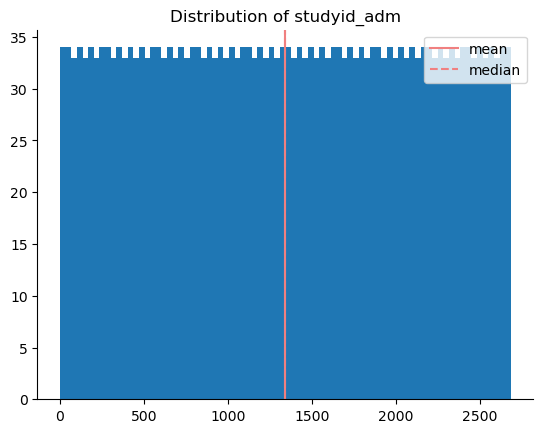

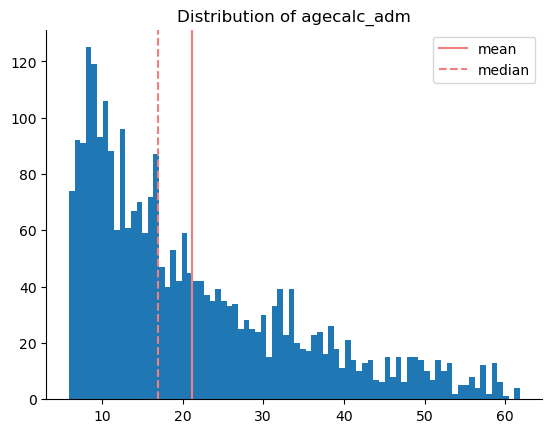

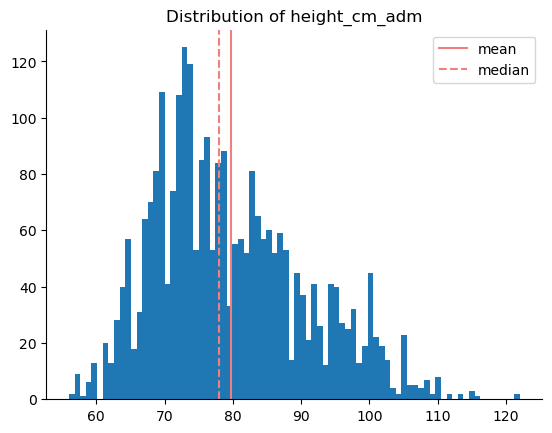

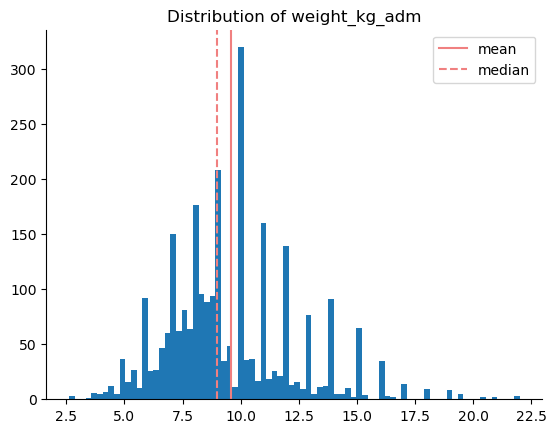

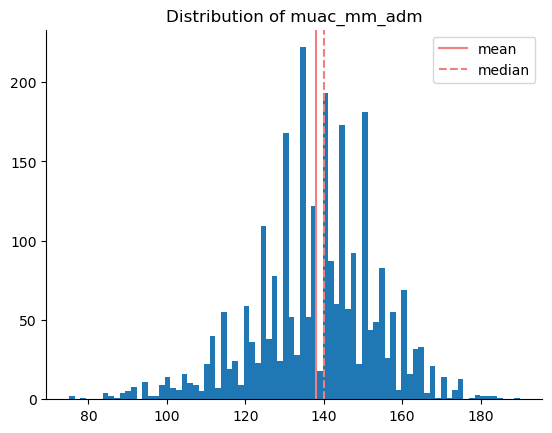

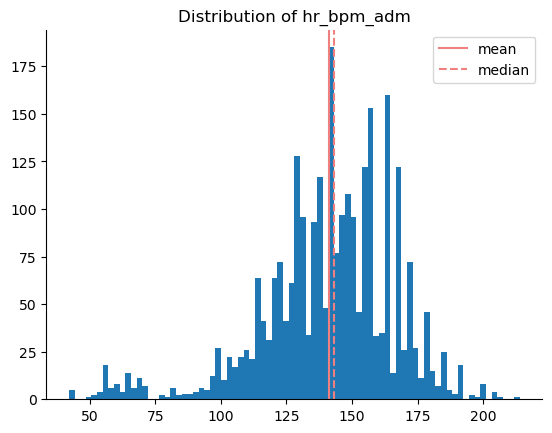

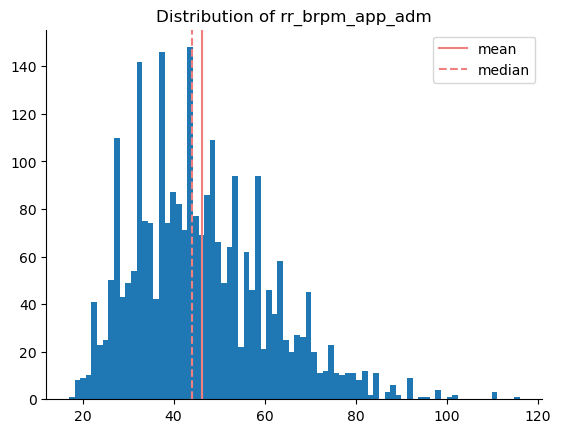

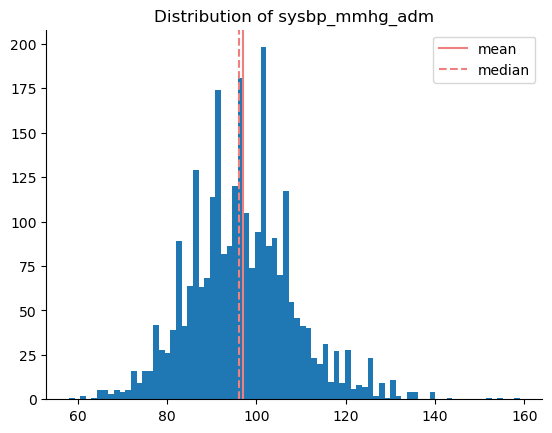

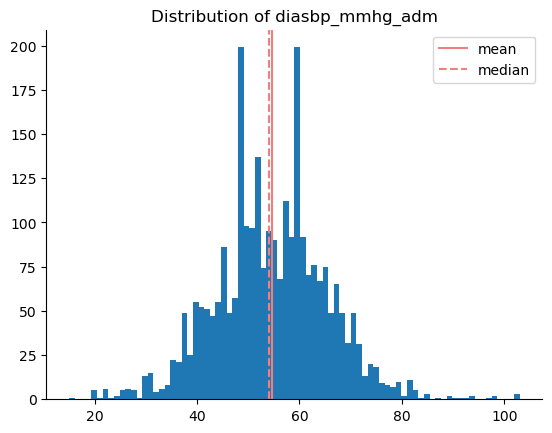

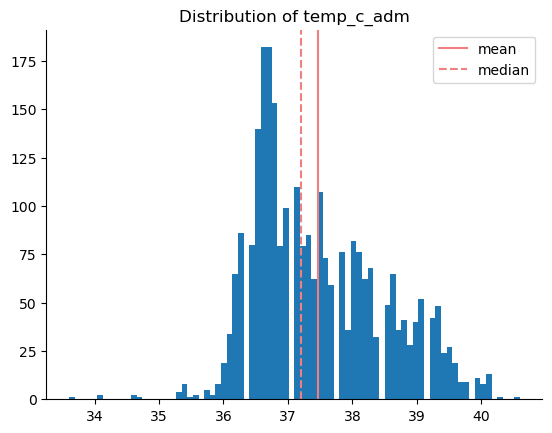

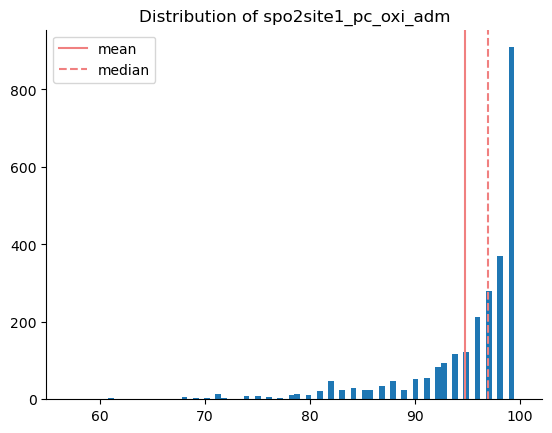

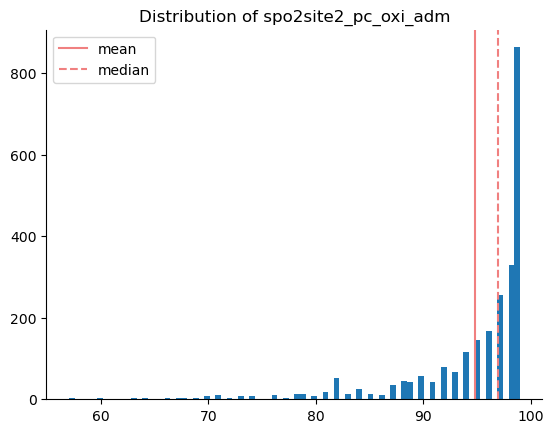

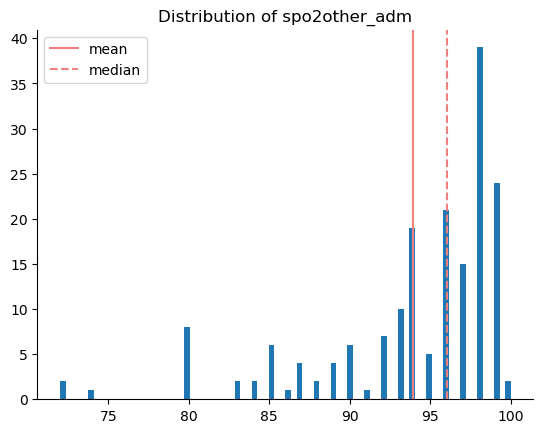

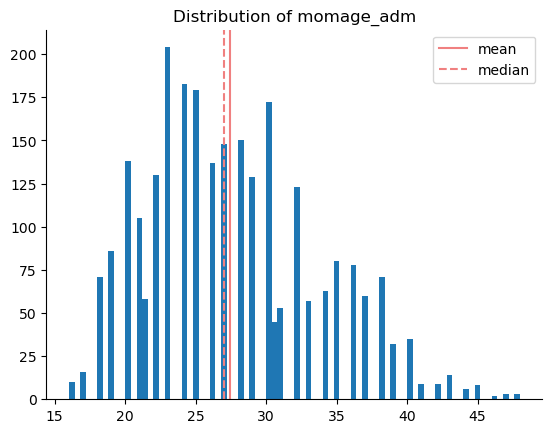

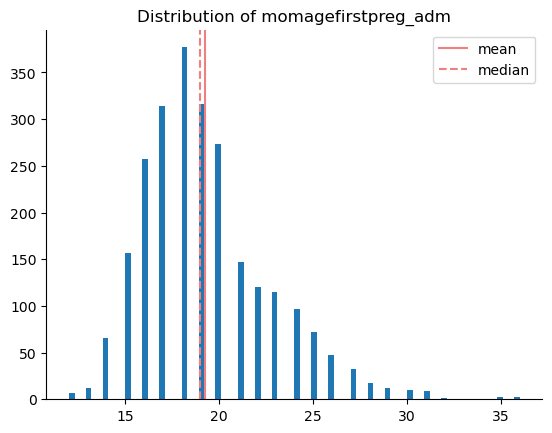

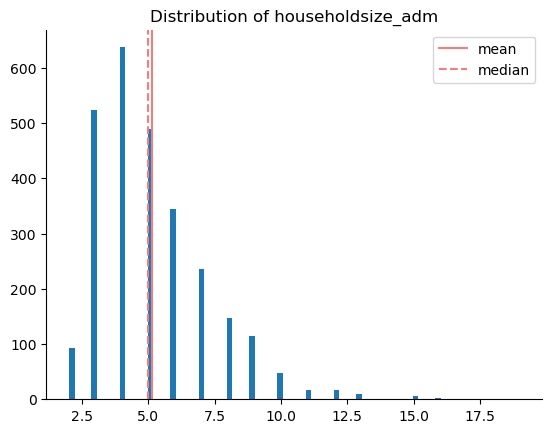

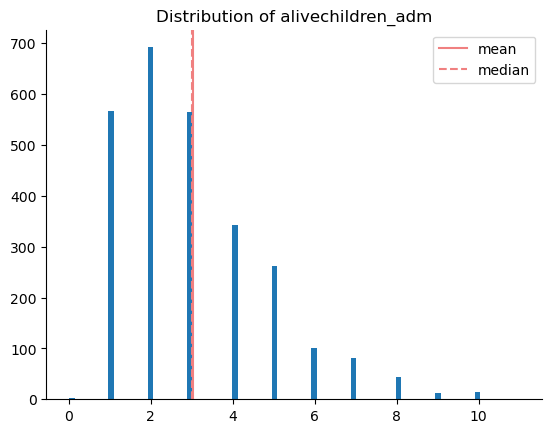

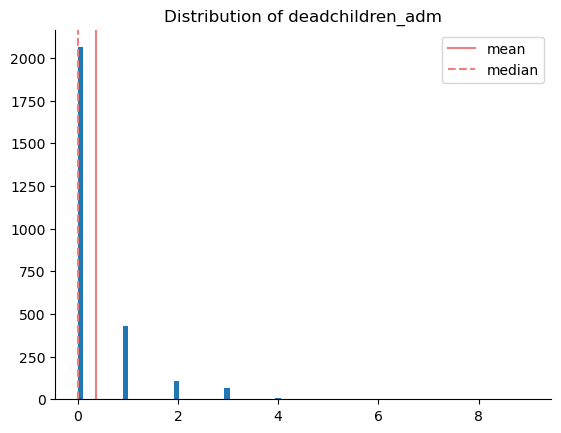

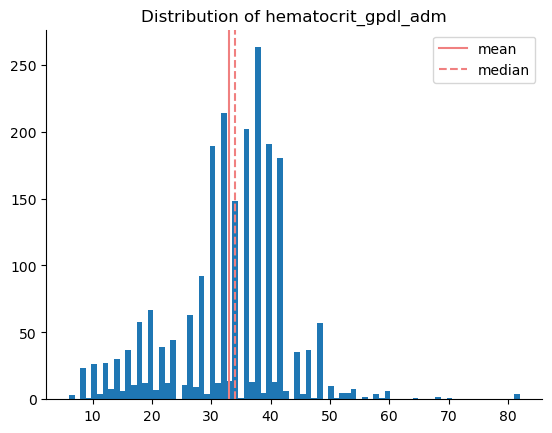

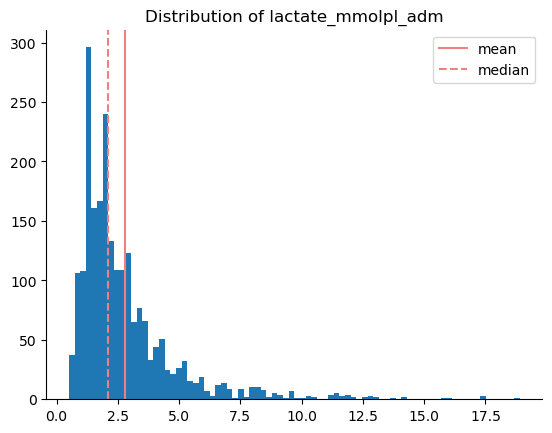

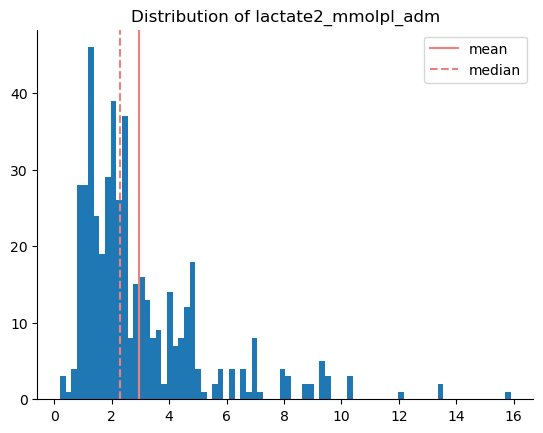

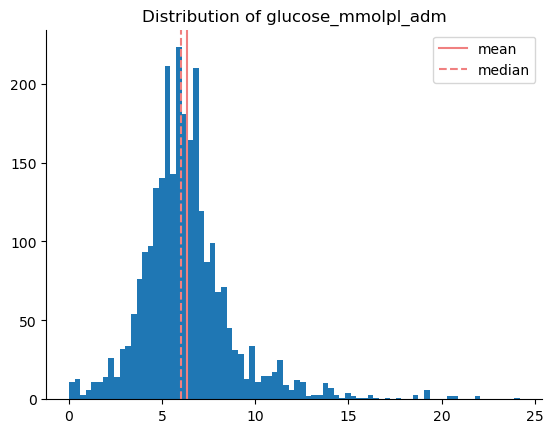

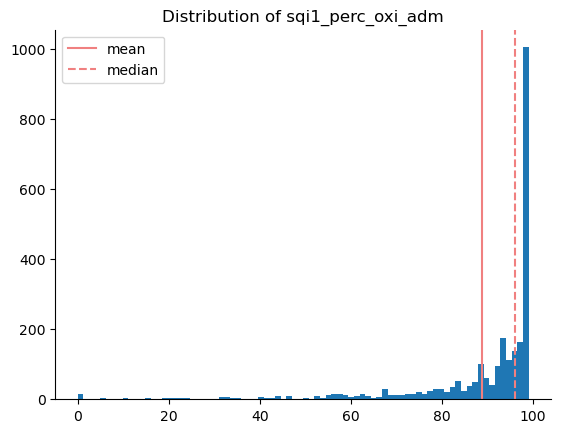

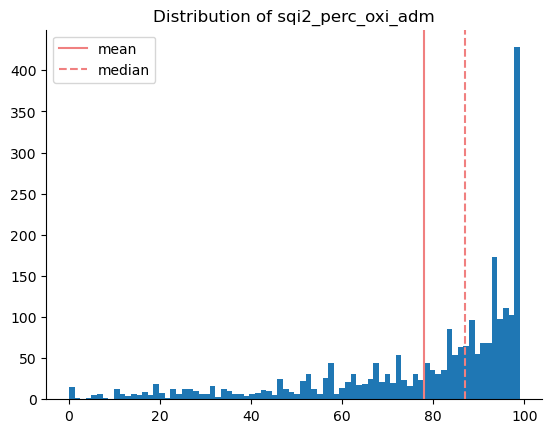

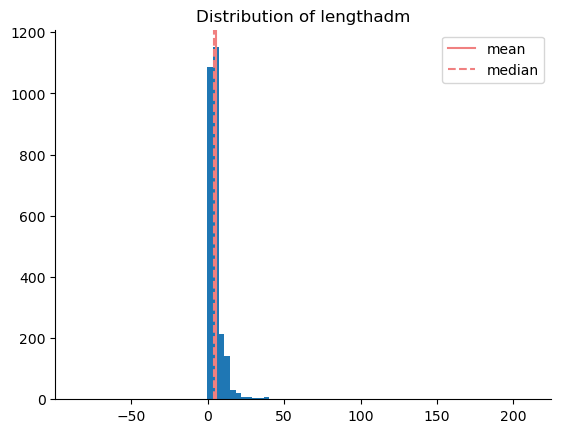

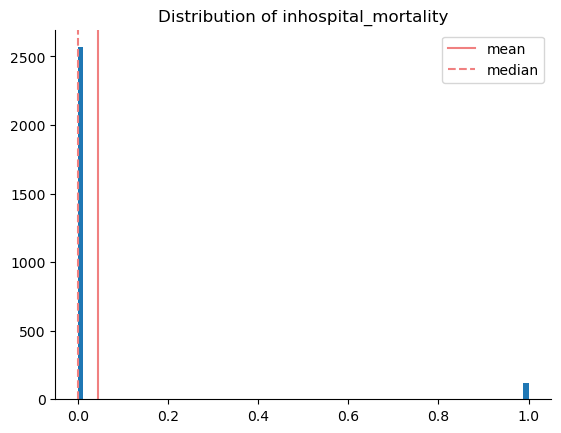

In [9]:
# Visulization of the distributions
for column in data.select_dtypes("number").columns:

    plt.hist(data[column], bins=80)

    plt.axvline(data[column].mean(), 0, 1000, label="mean", color="lightcoral")
    plt.axvline(data[column].median(), 0, 1000, label="median", color="lightcoral", linestyle="--")

    plt.title(f"Distribution of {column}")
    sns.despine()
    plt.legend()
    plt.show()

#### Categorical Columns

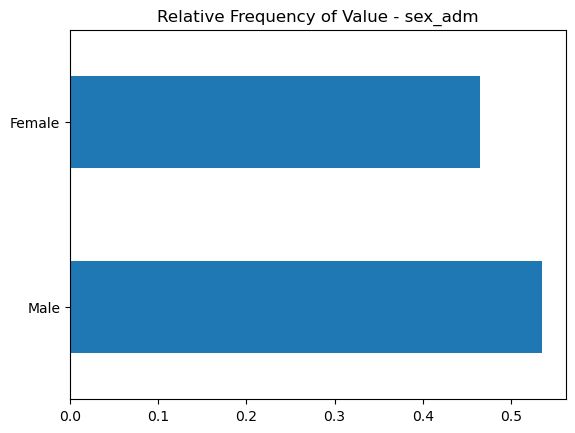

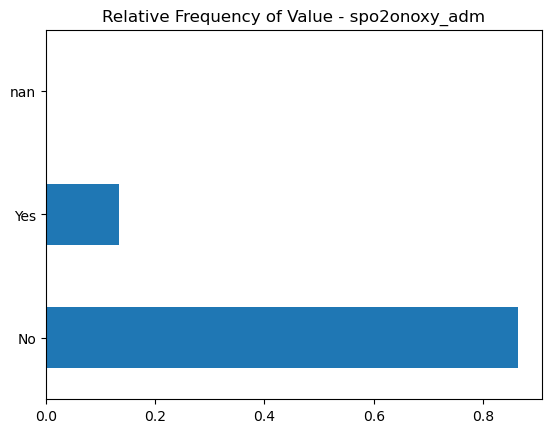

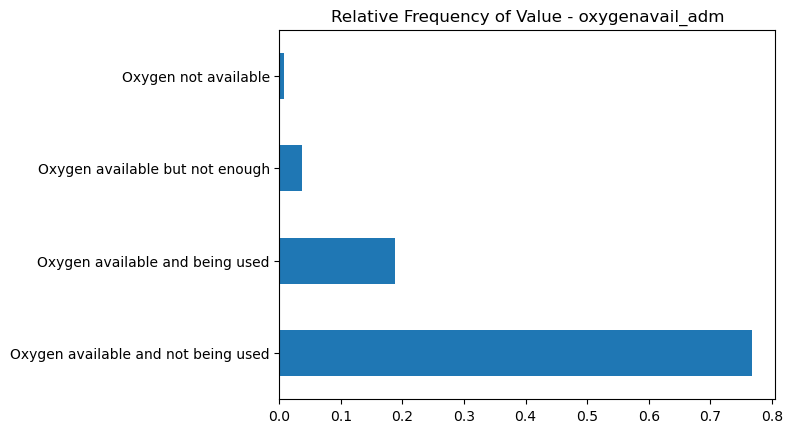

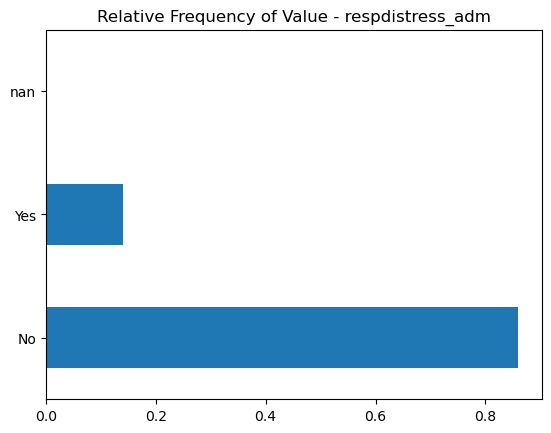

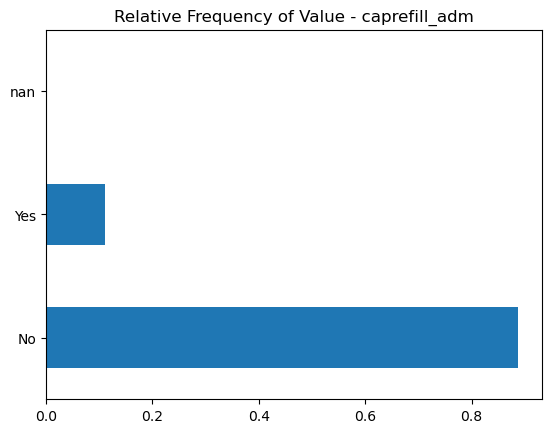

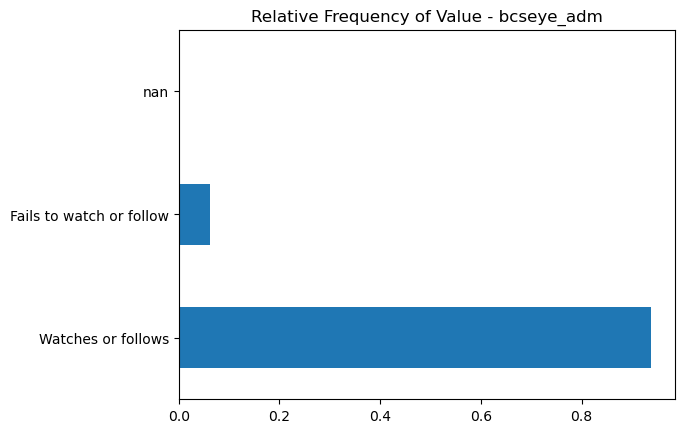

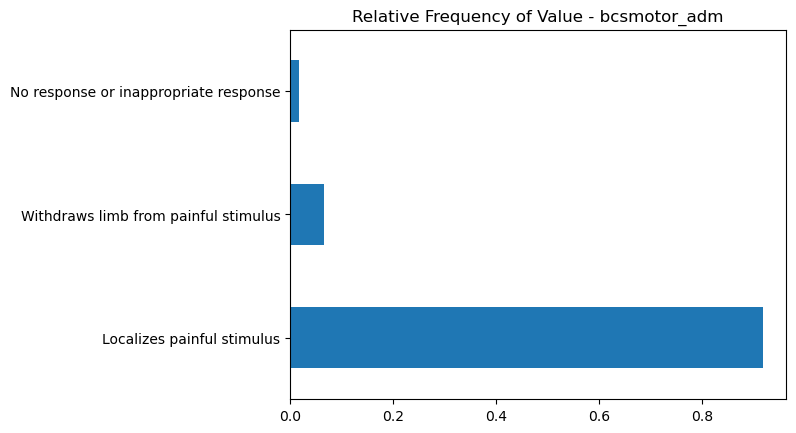

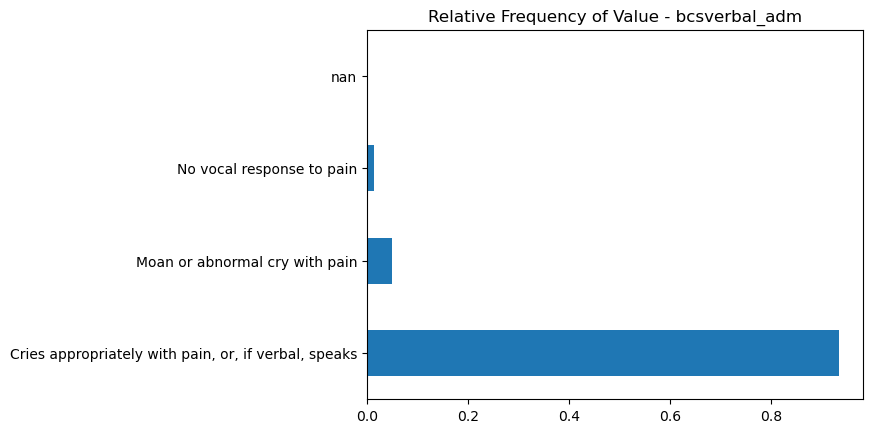

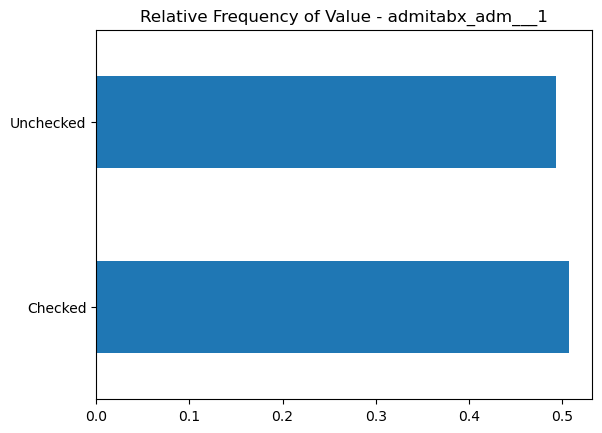

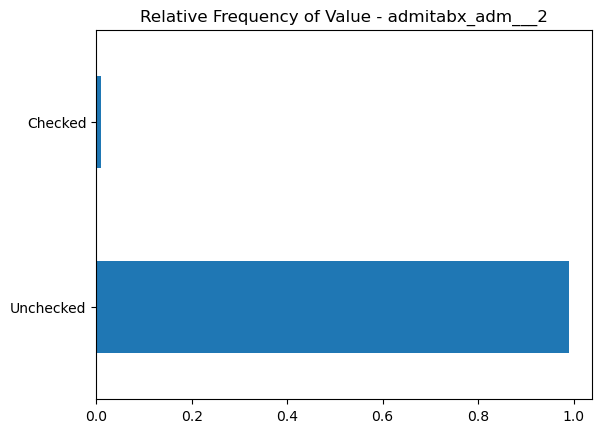

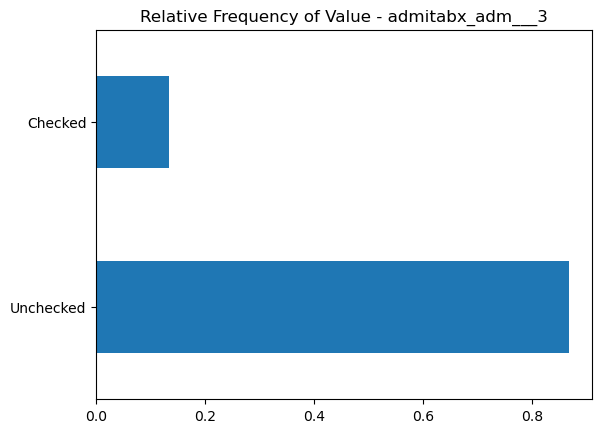

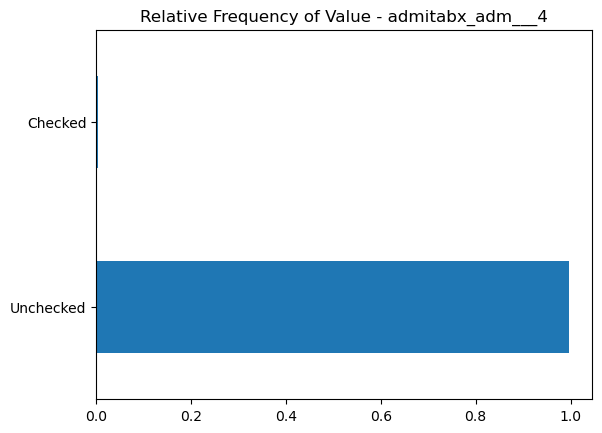

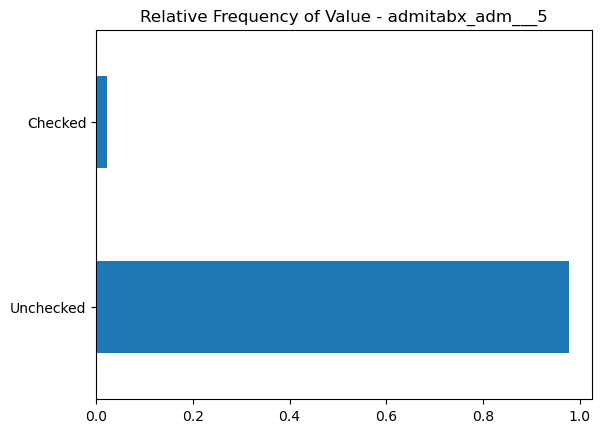

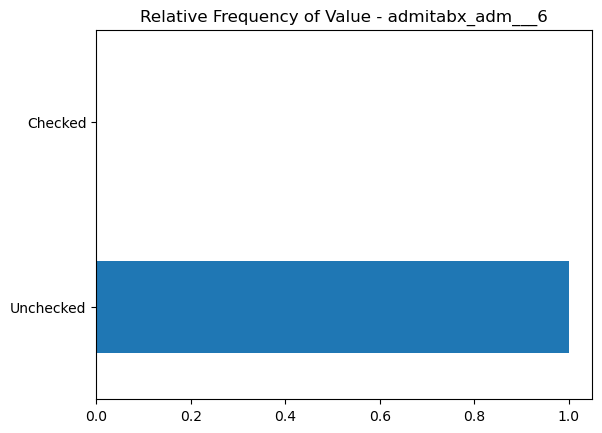

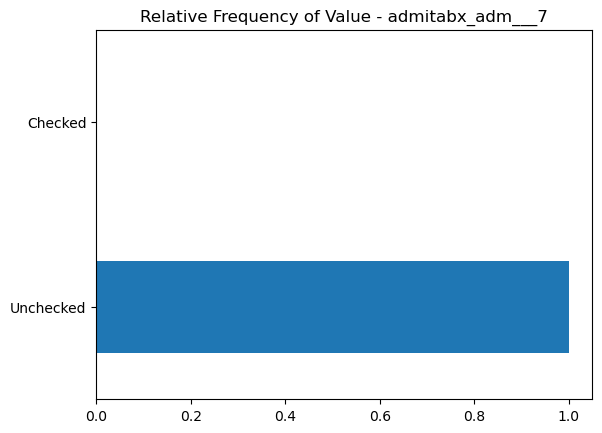

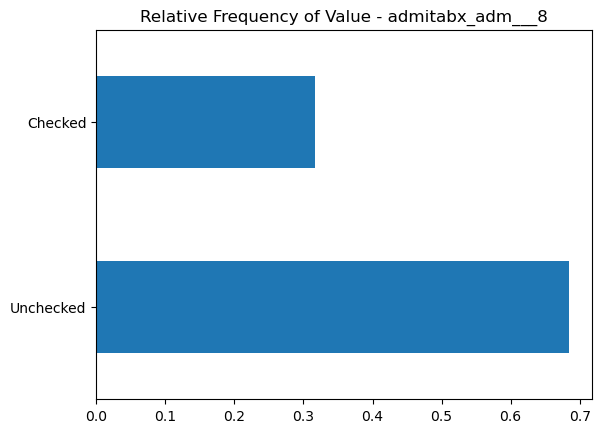

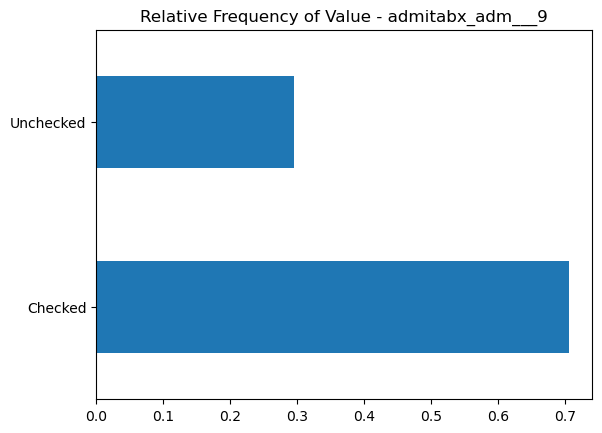

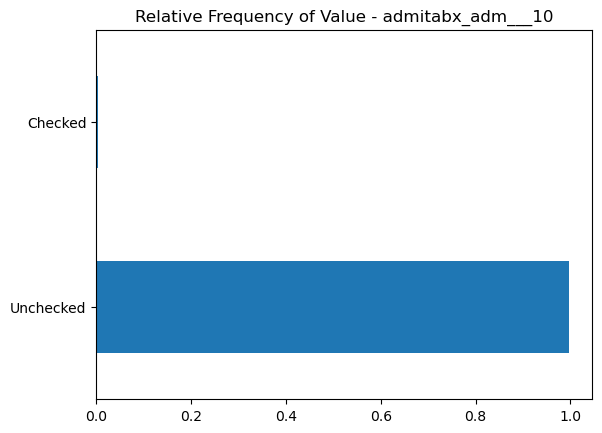

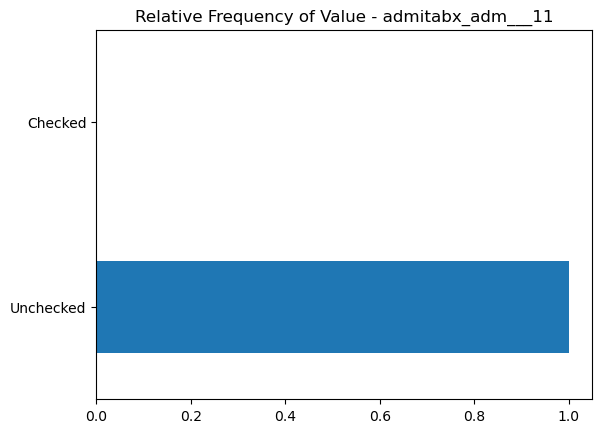

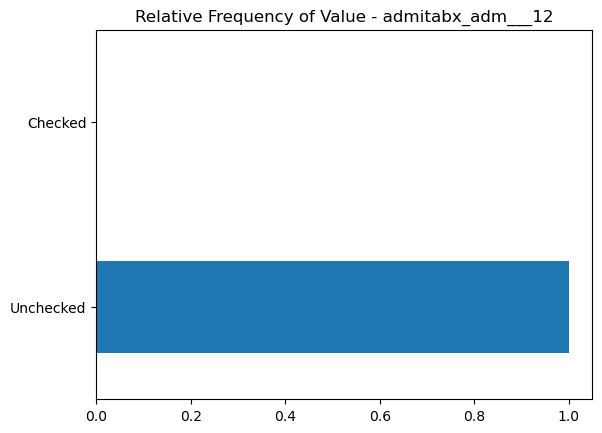

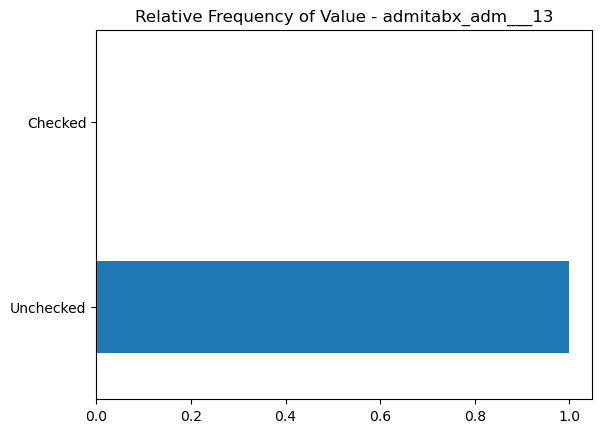

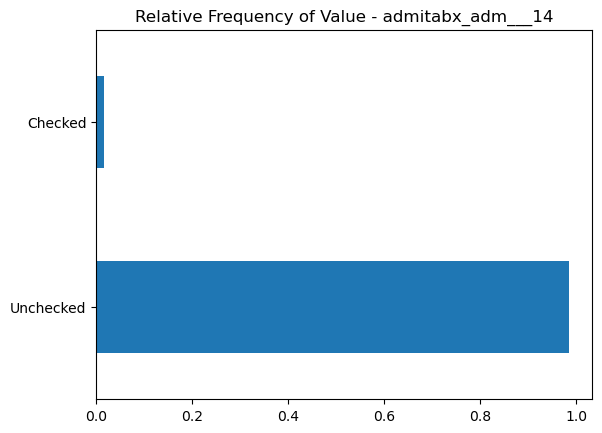

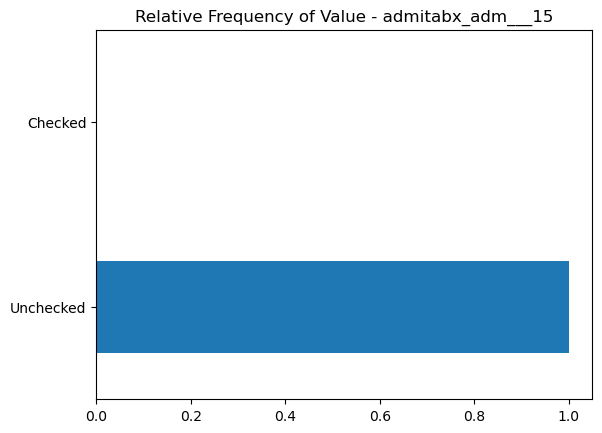

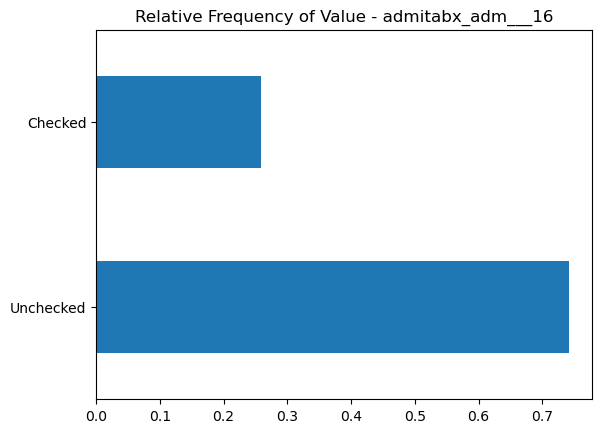

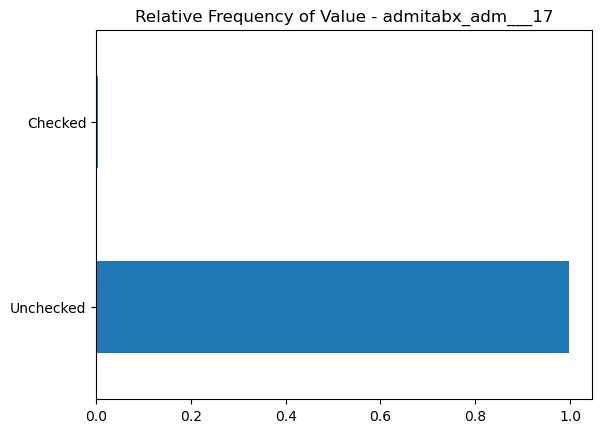

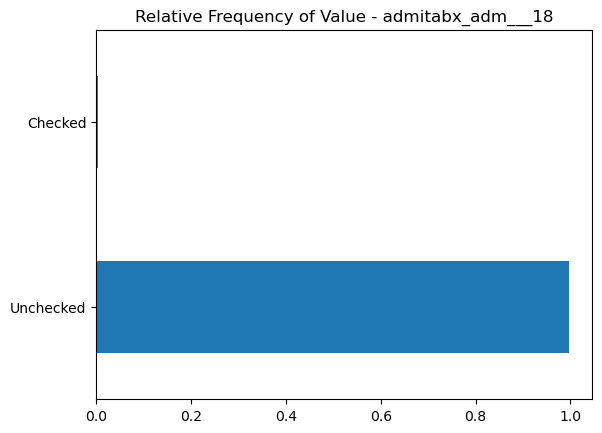

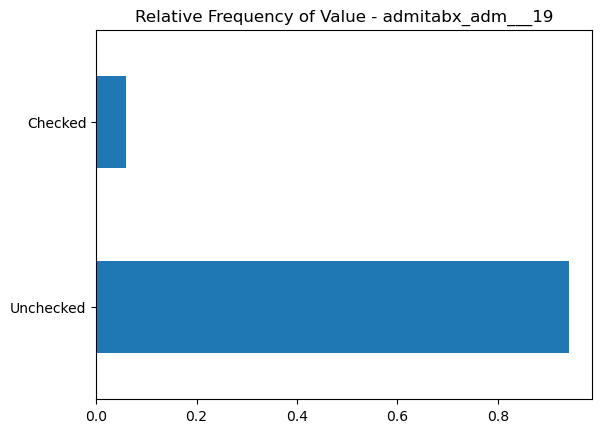

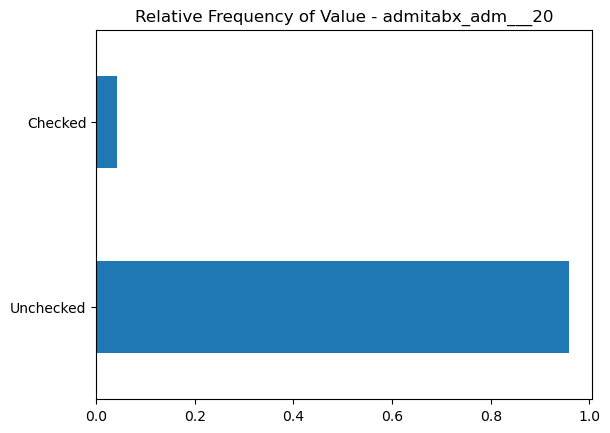

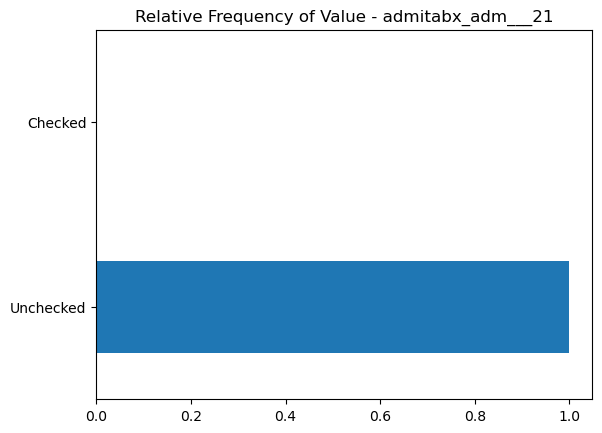

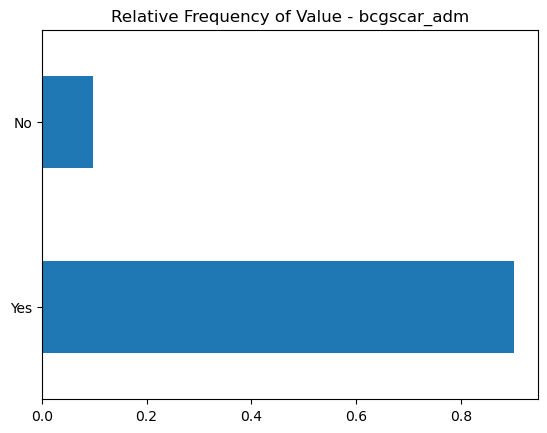

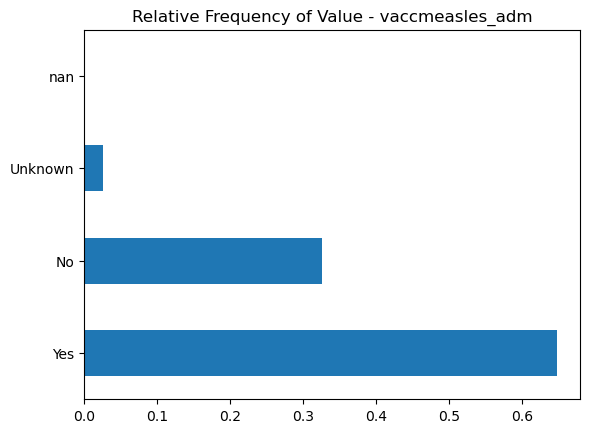

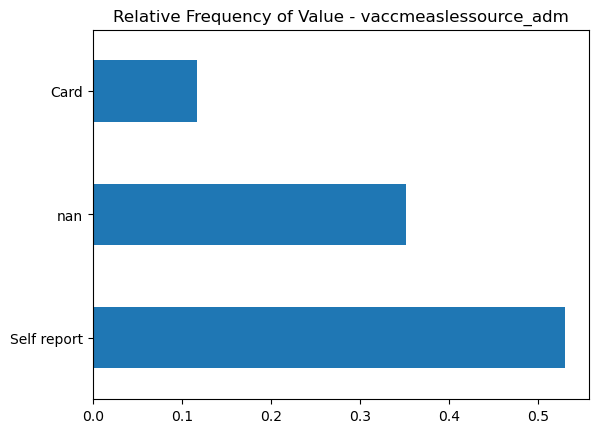

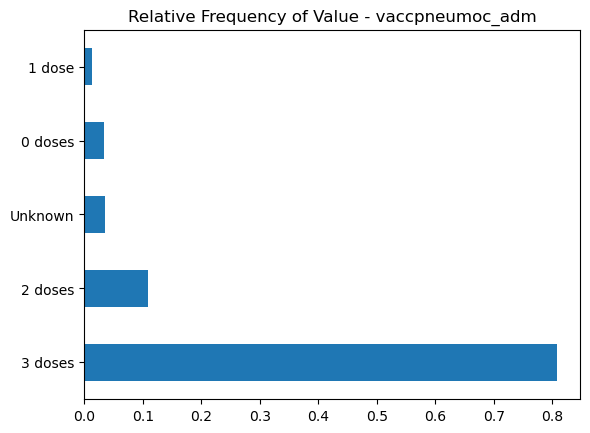

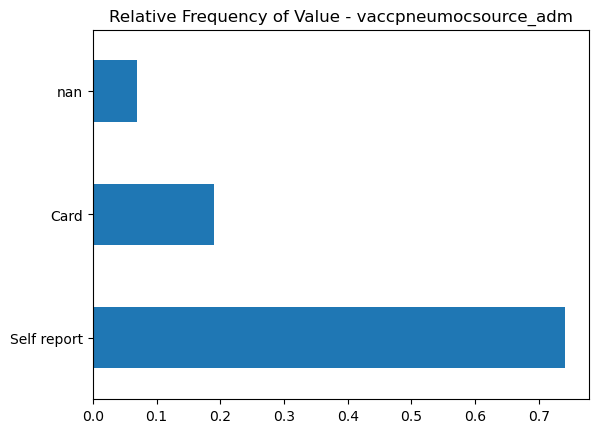

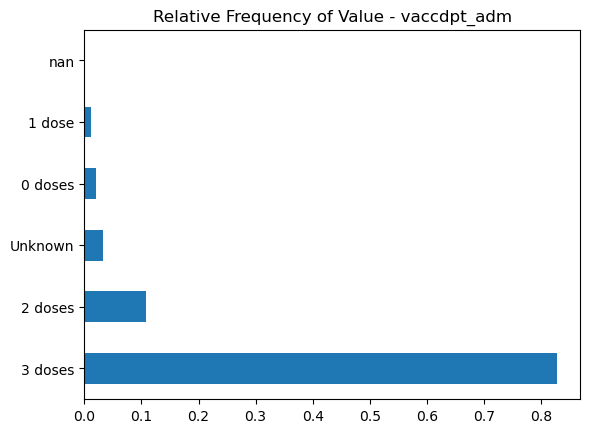

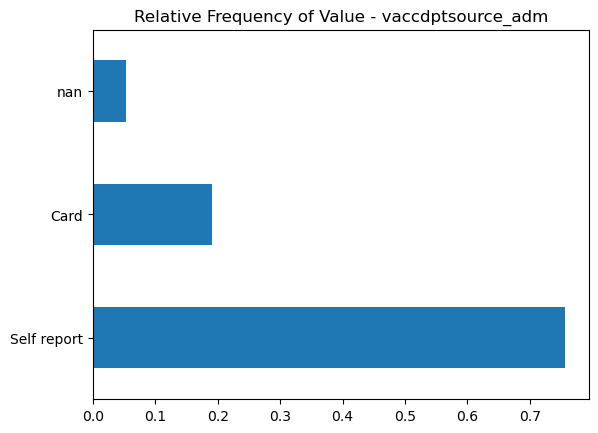

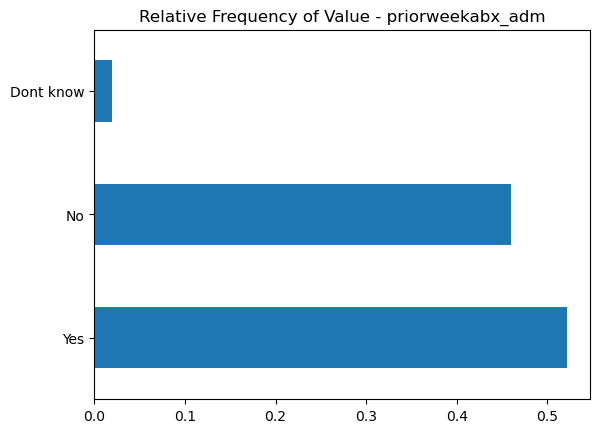

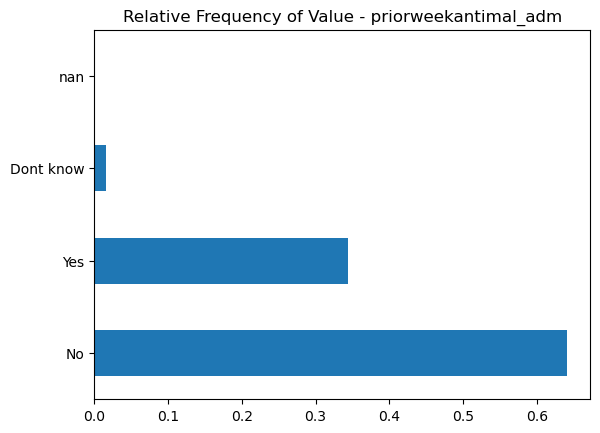

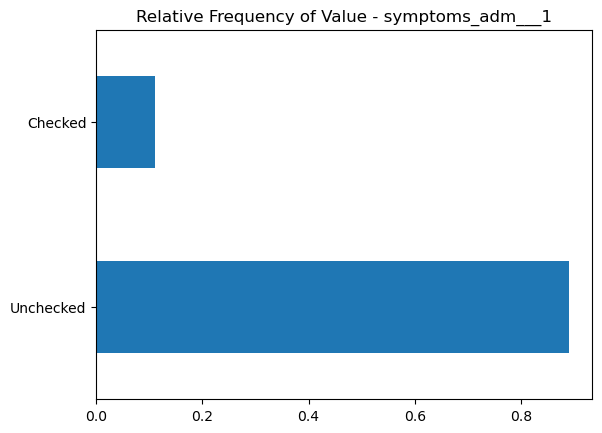

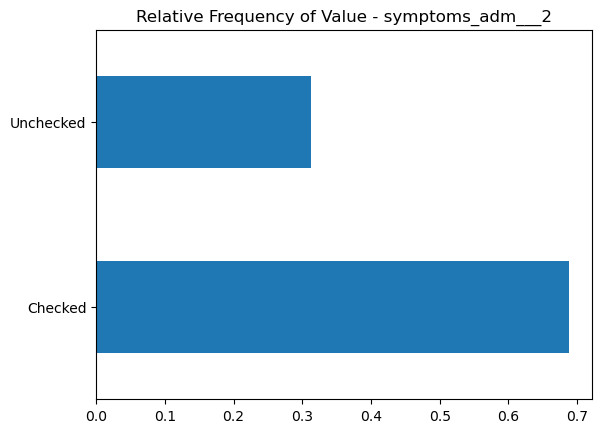

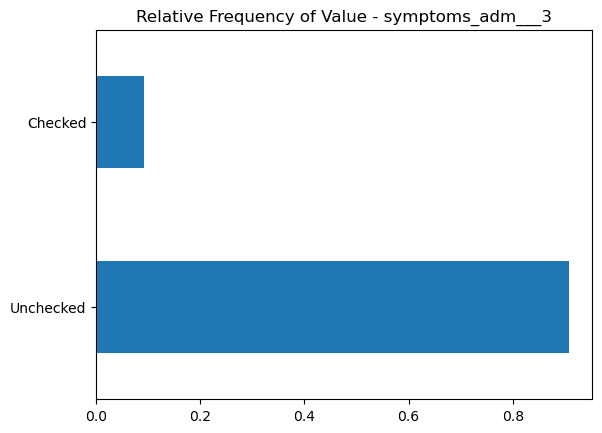

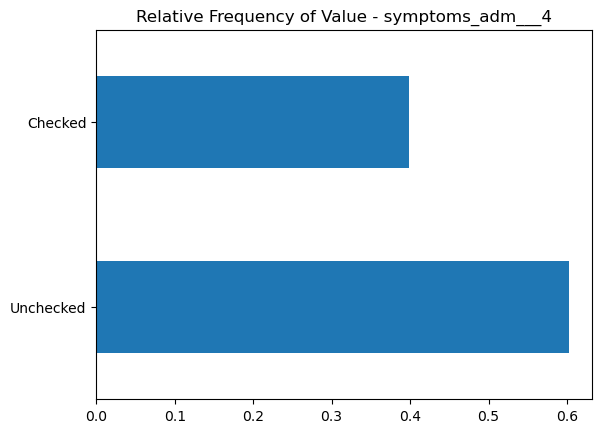

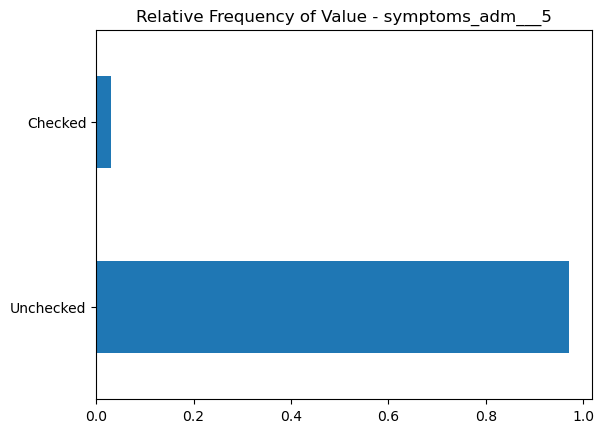

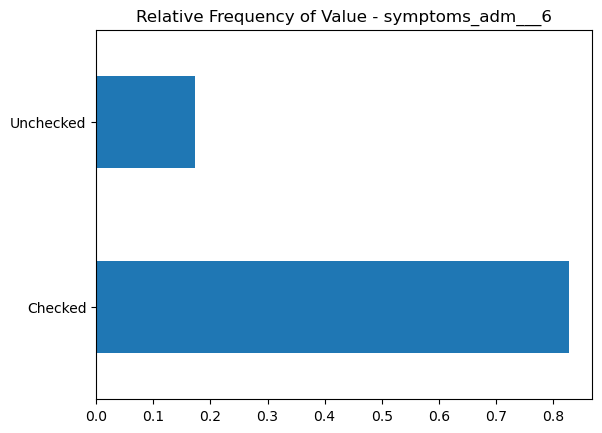

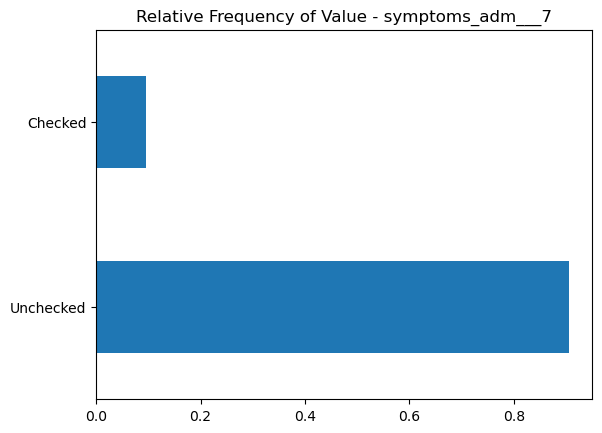

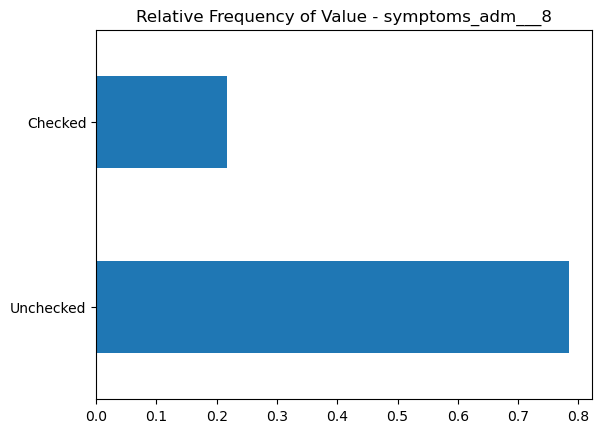

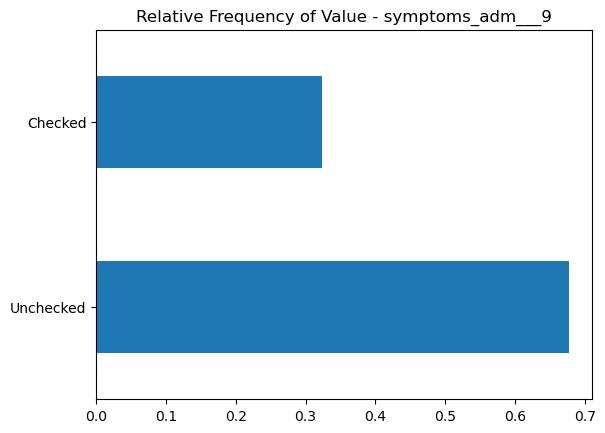

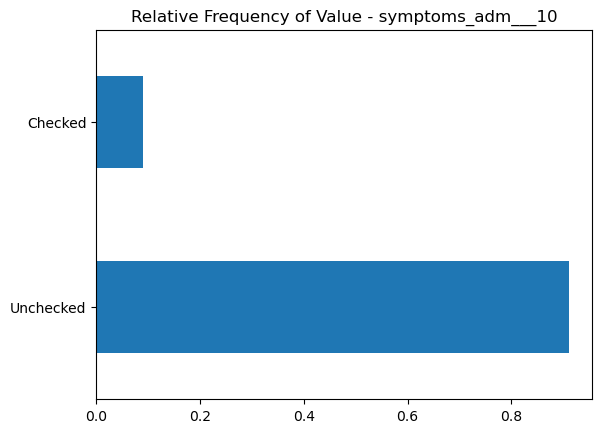

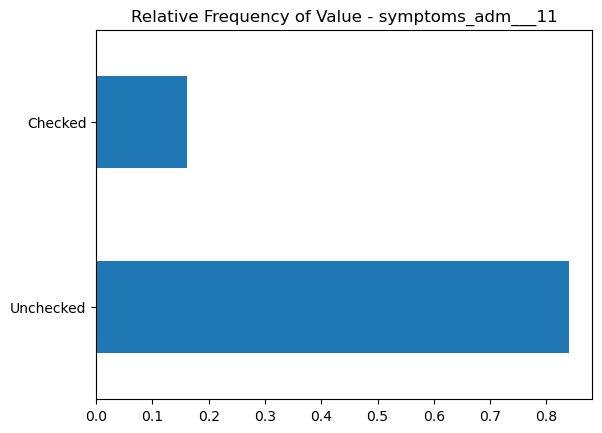

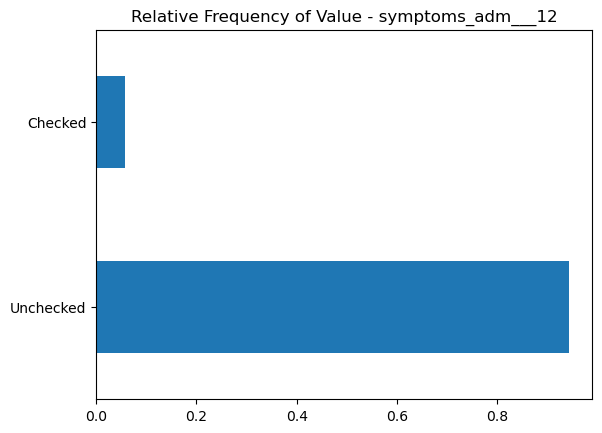

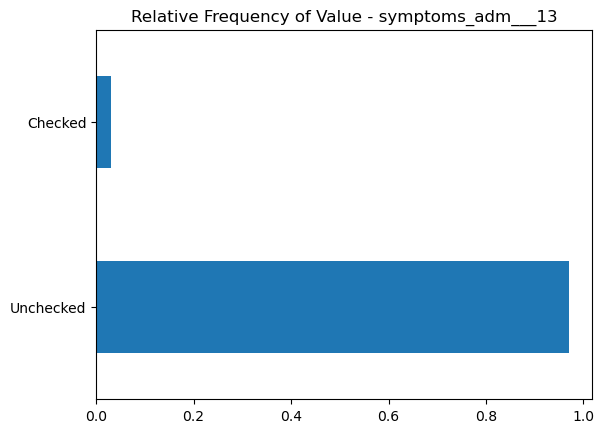

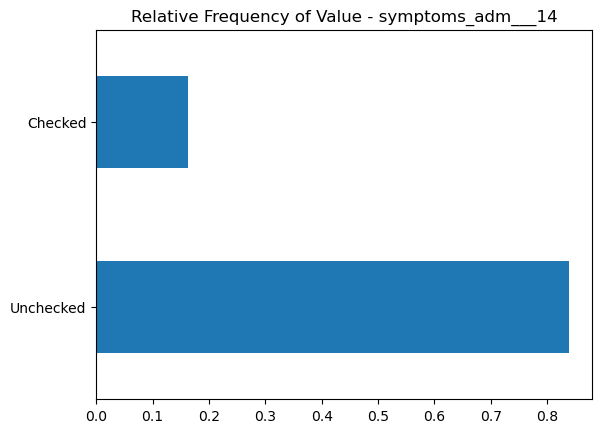

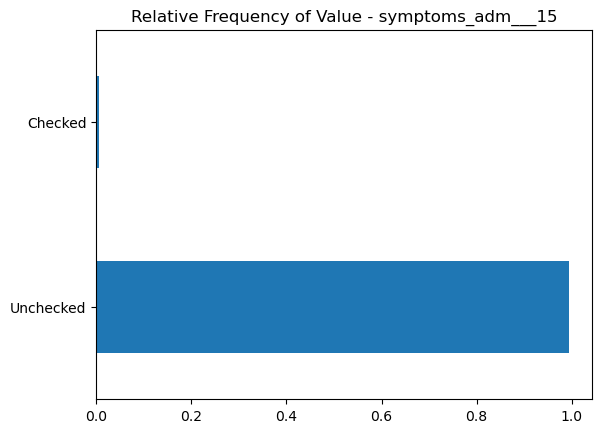

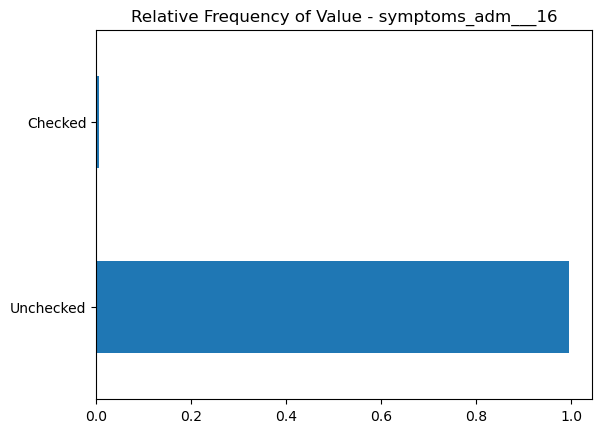

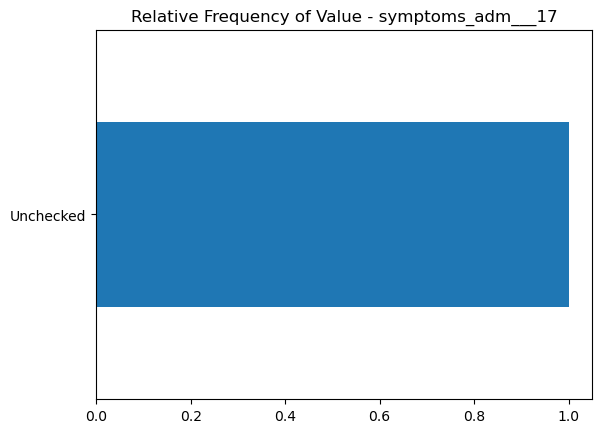

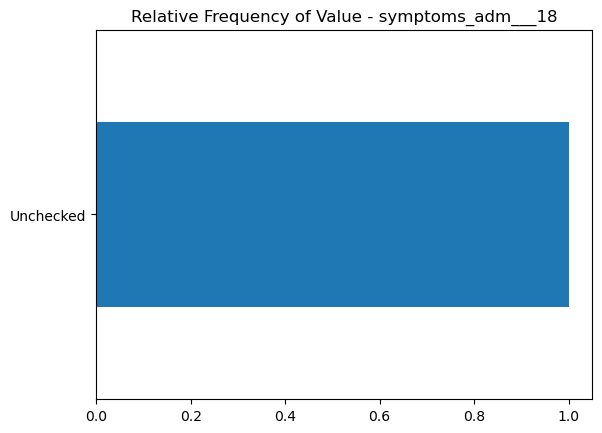

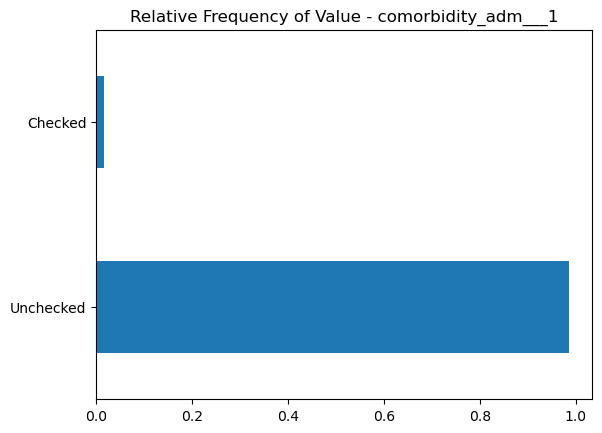

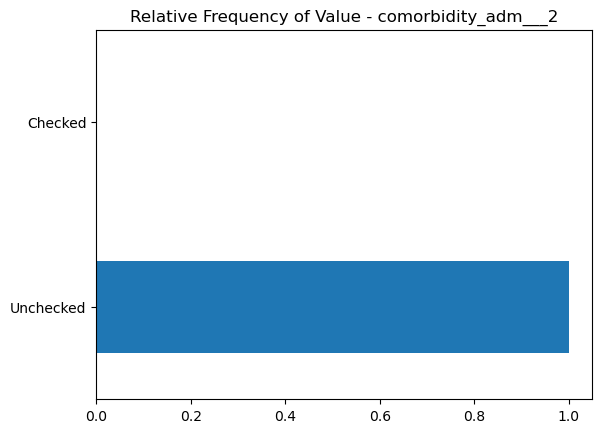

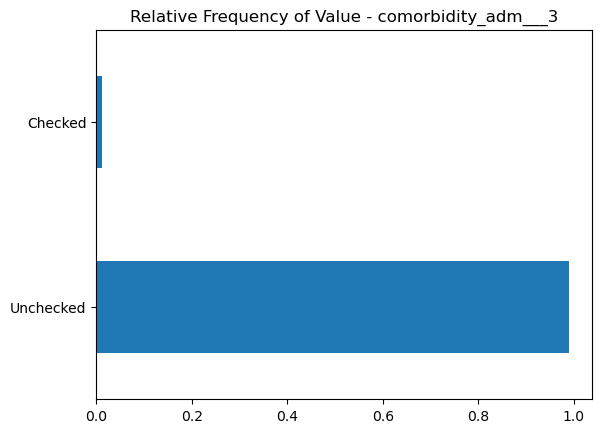

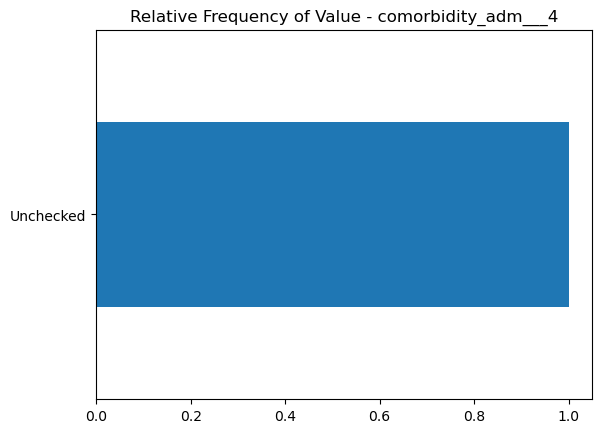

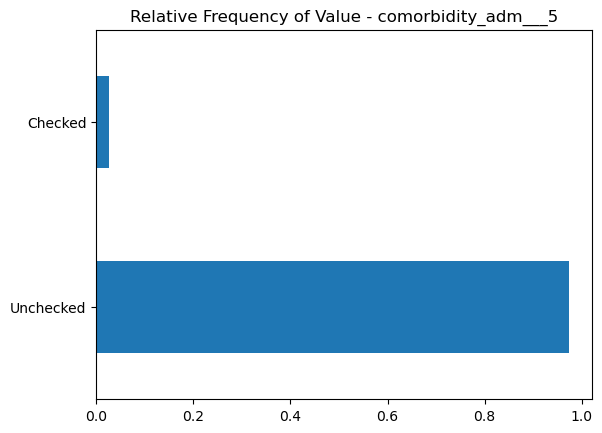

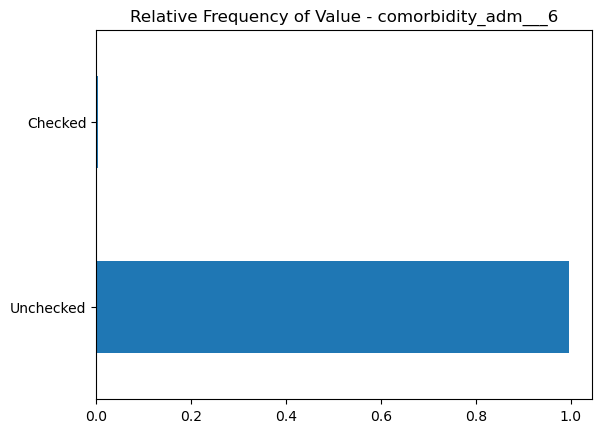

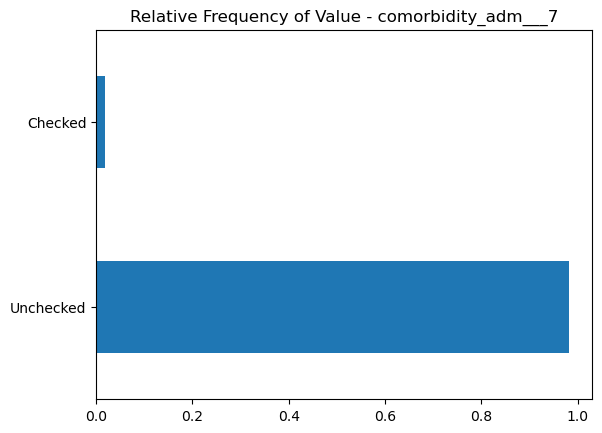

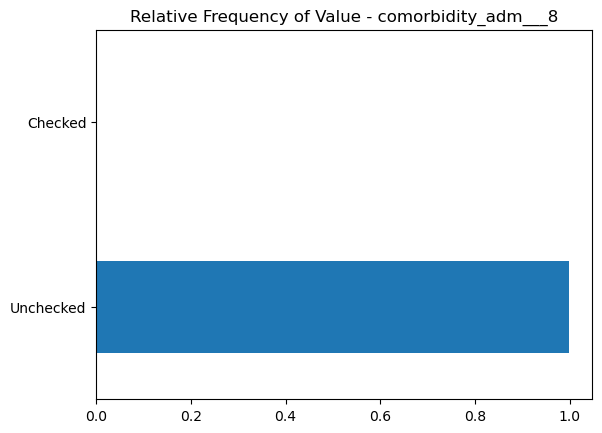

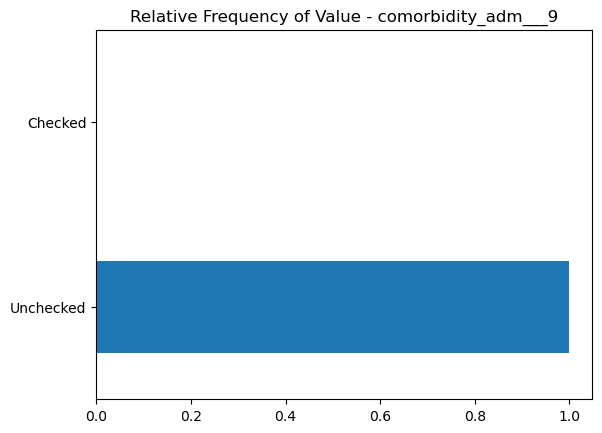

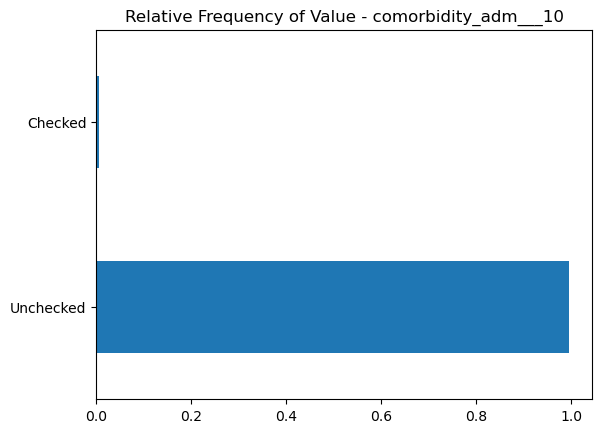

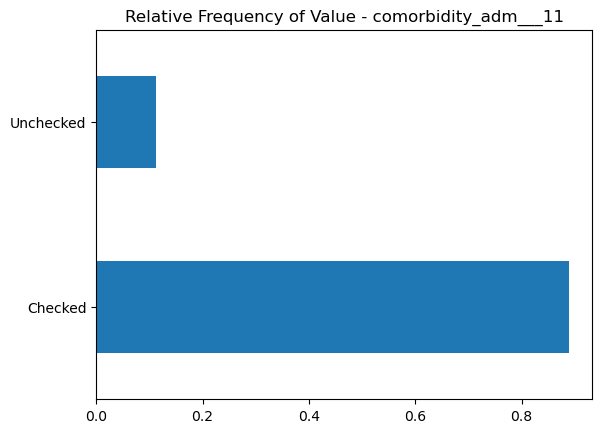

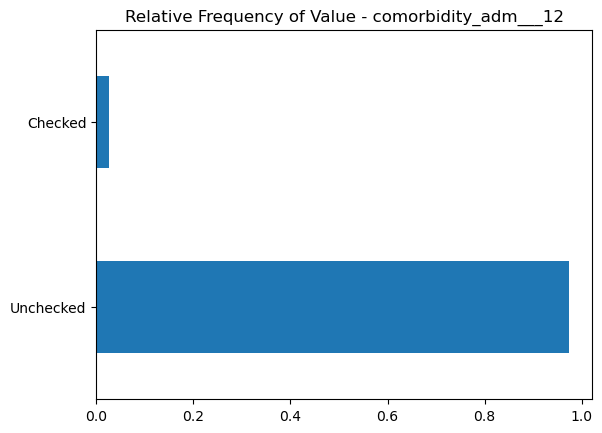

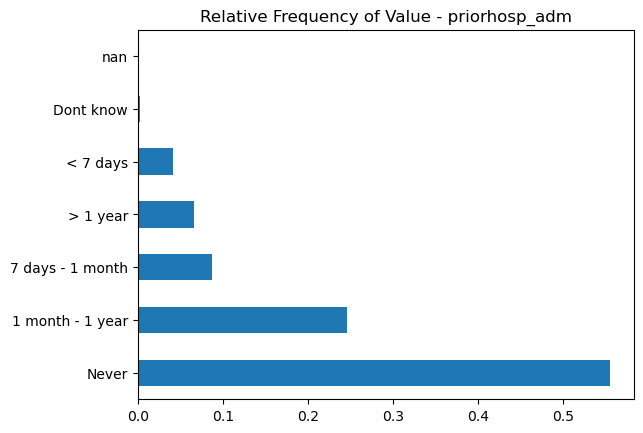

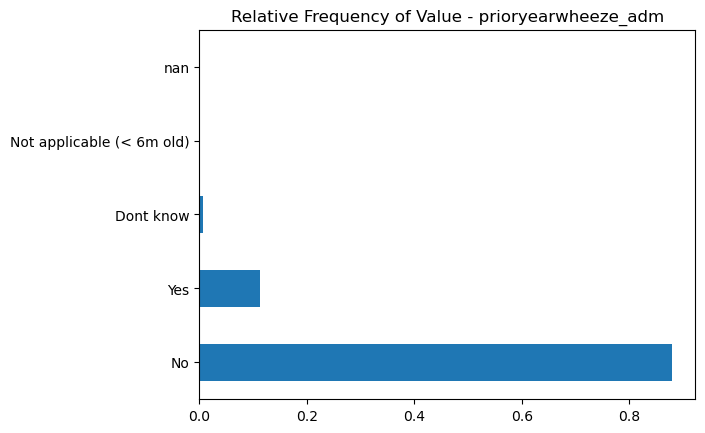

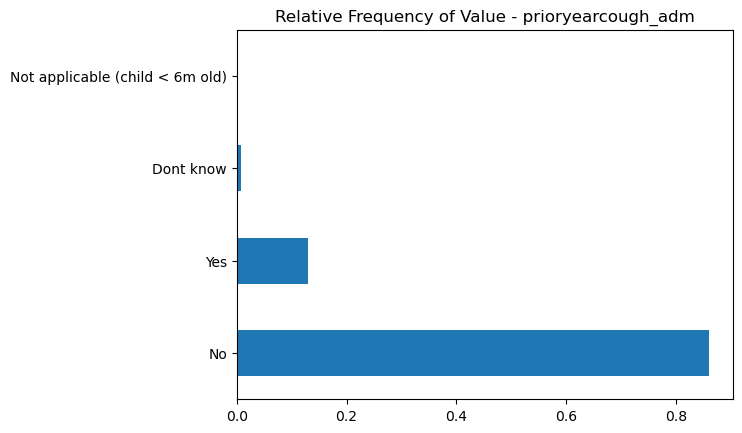

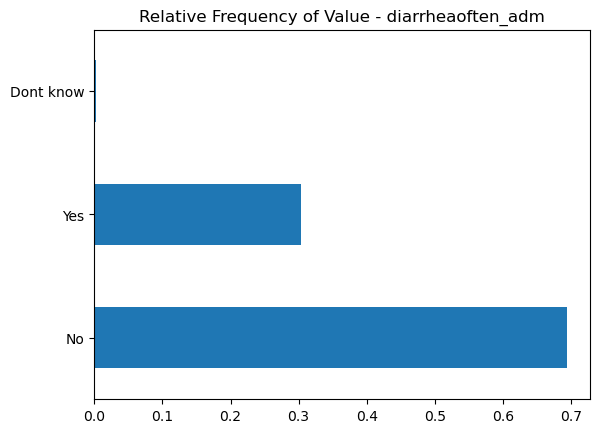

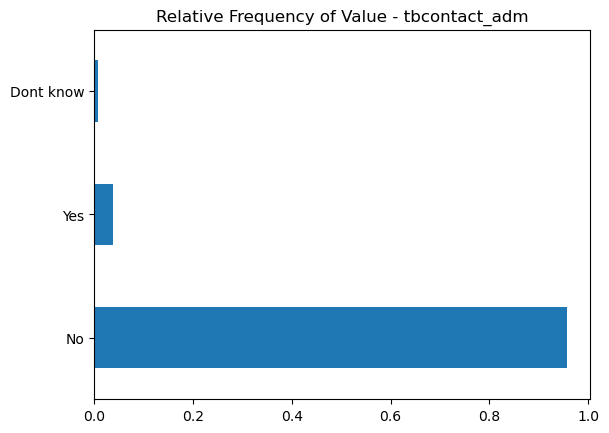

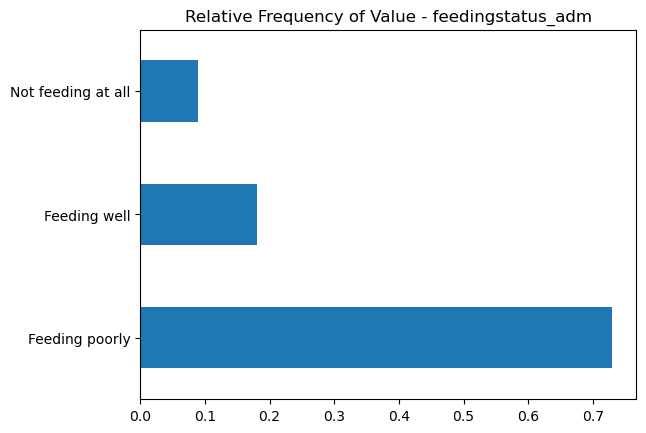

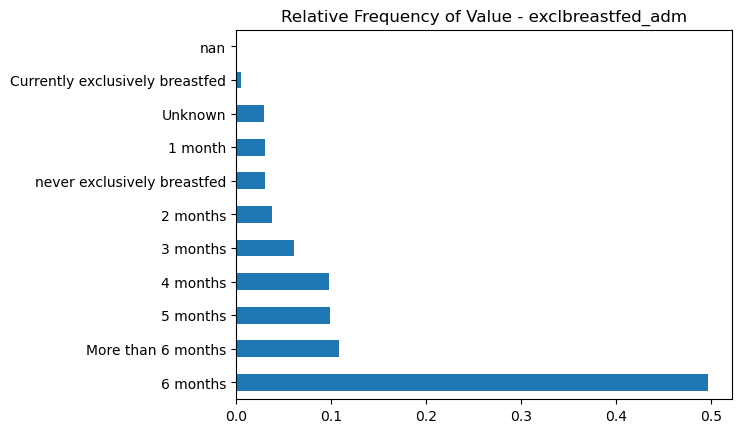

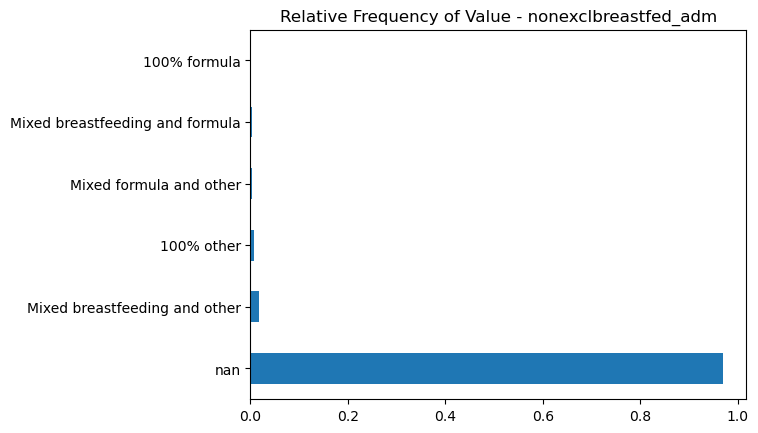

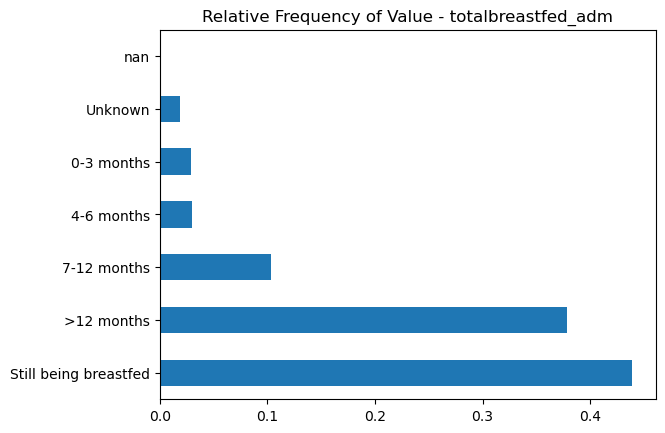

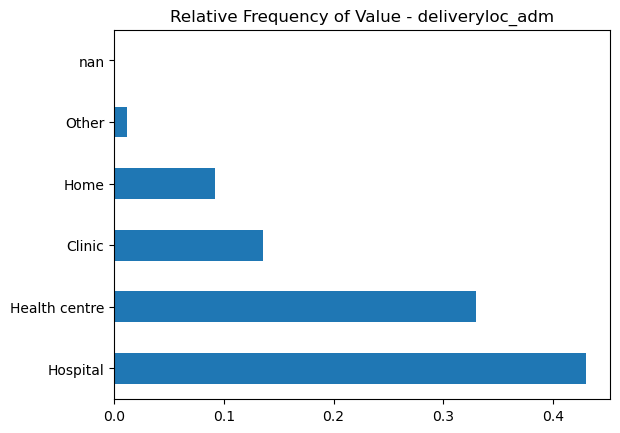

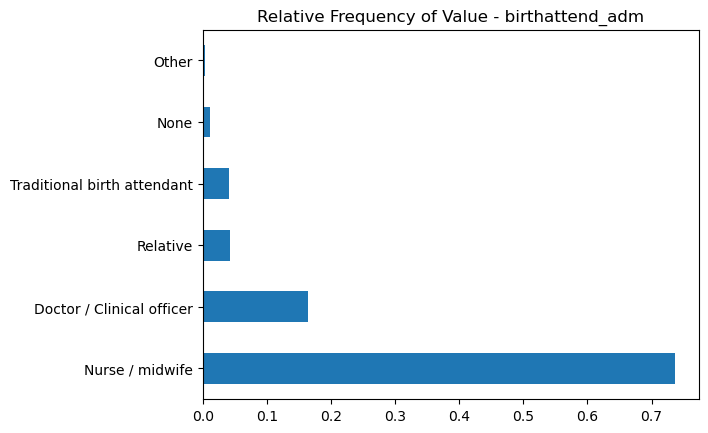

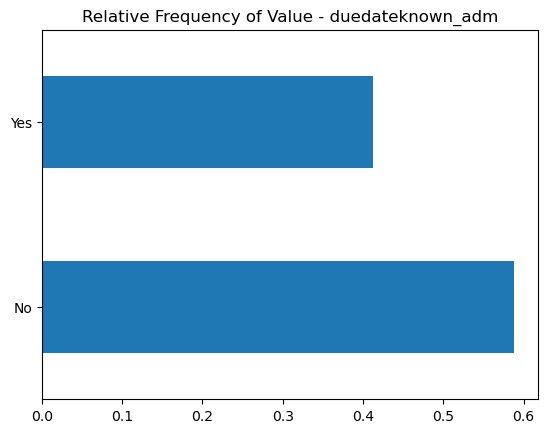

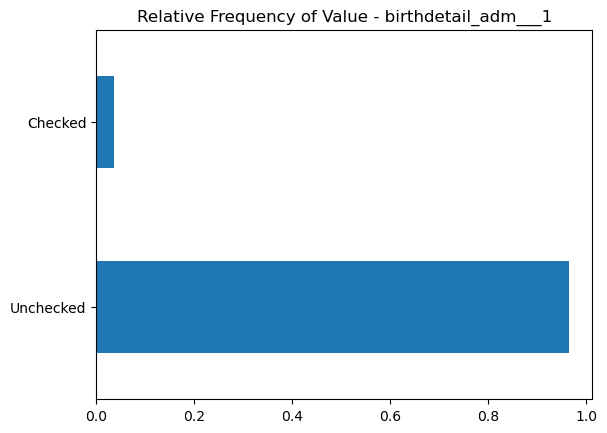

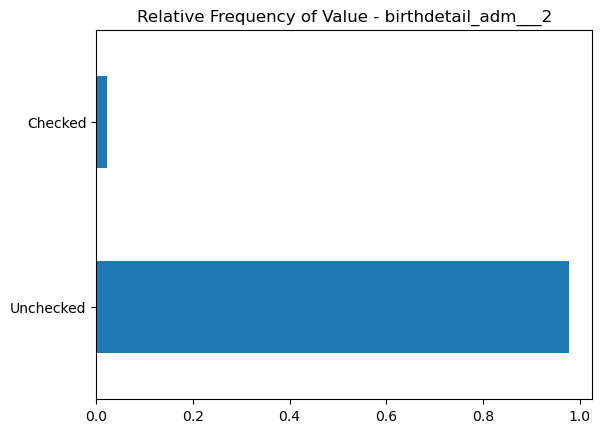

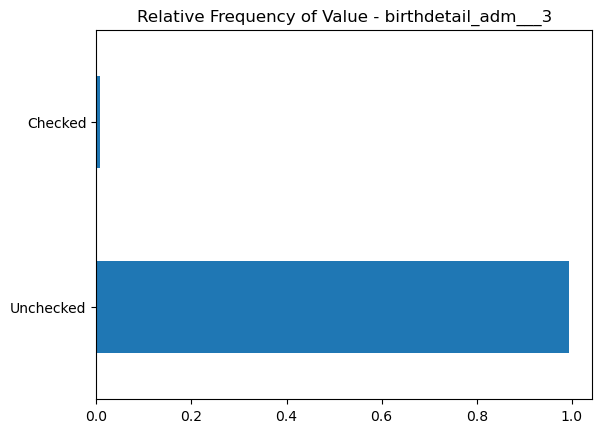

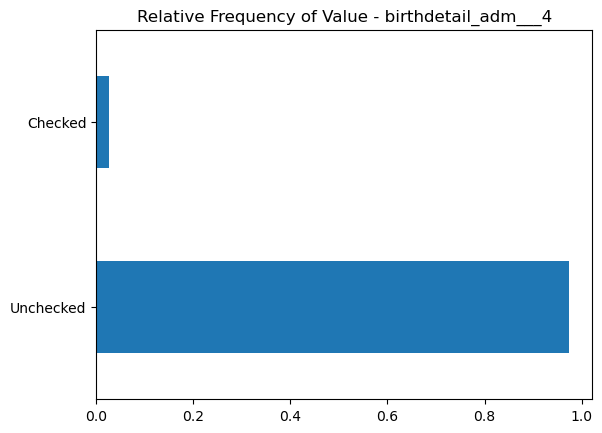

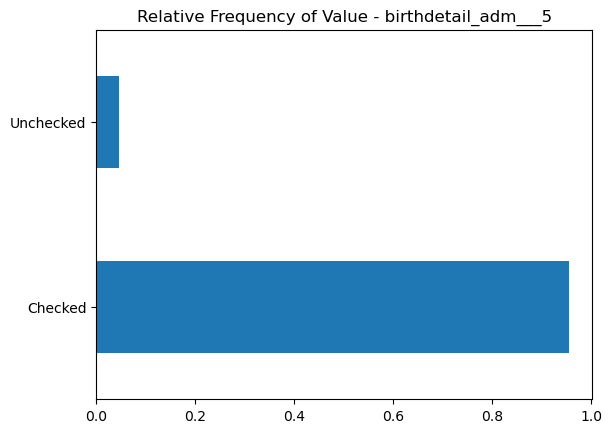

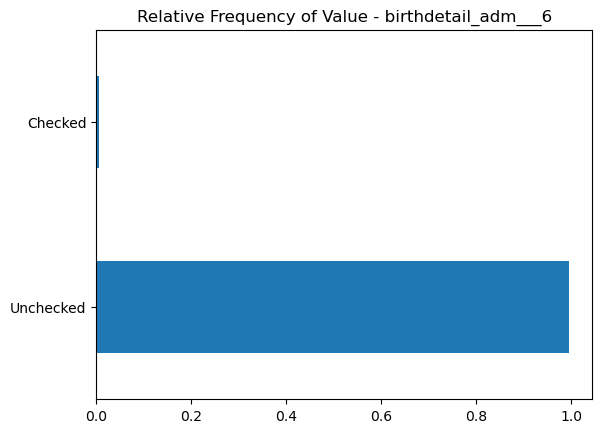

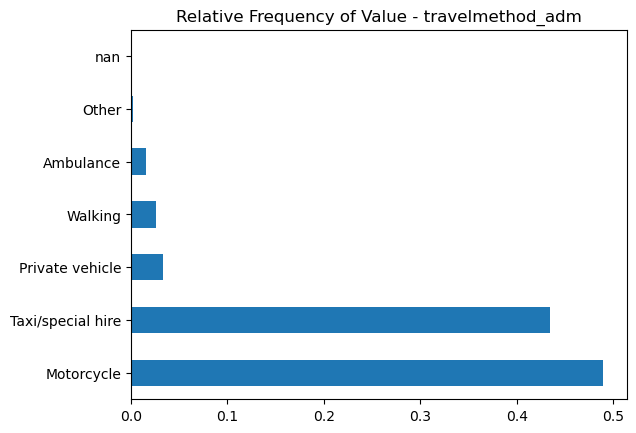

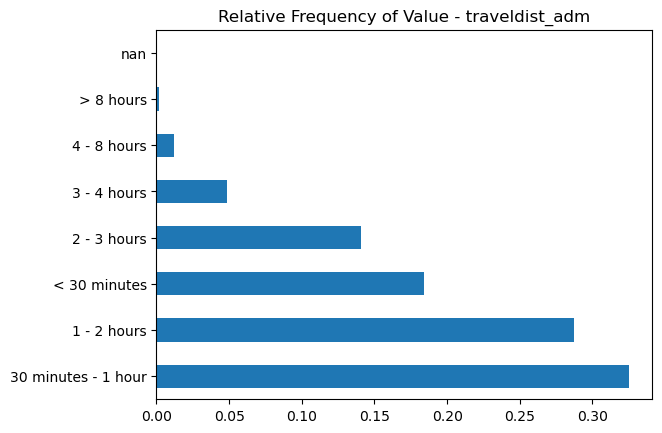

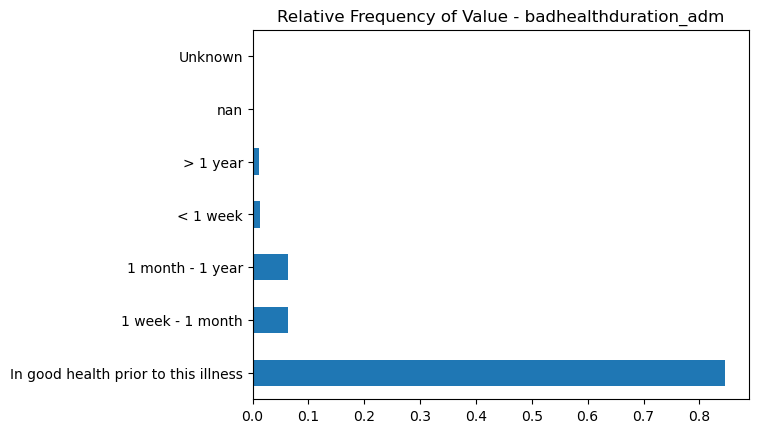

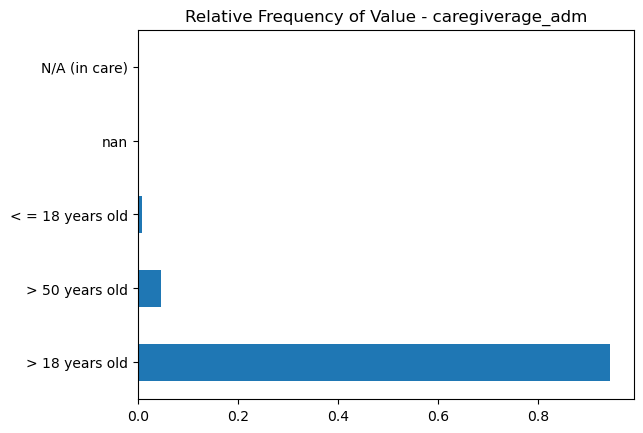

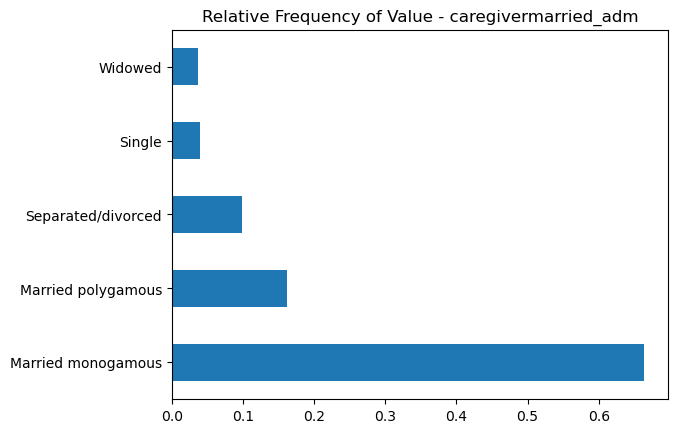

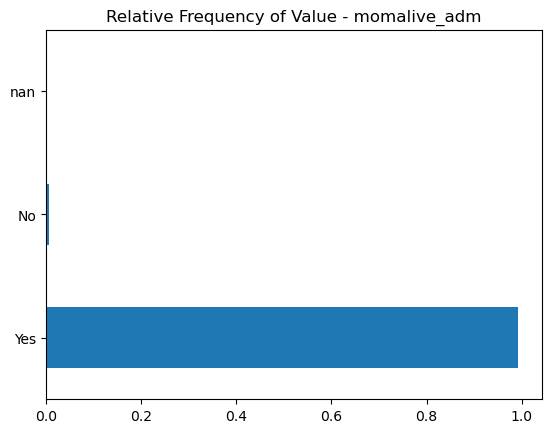

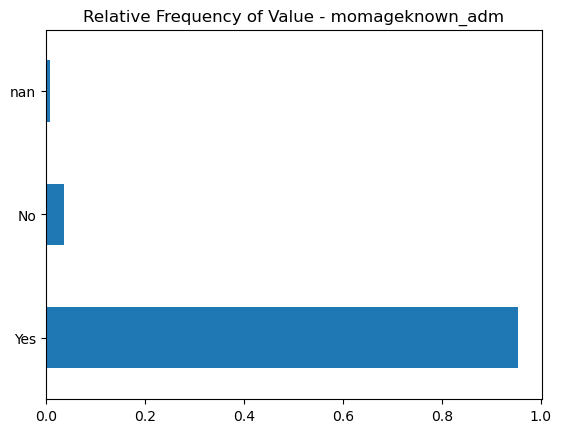

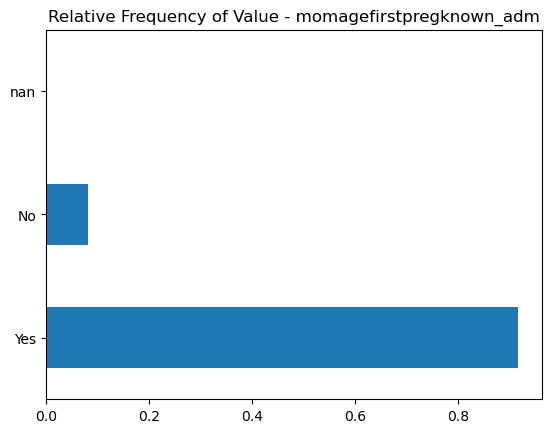

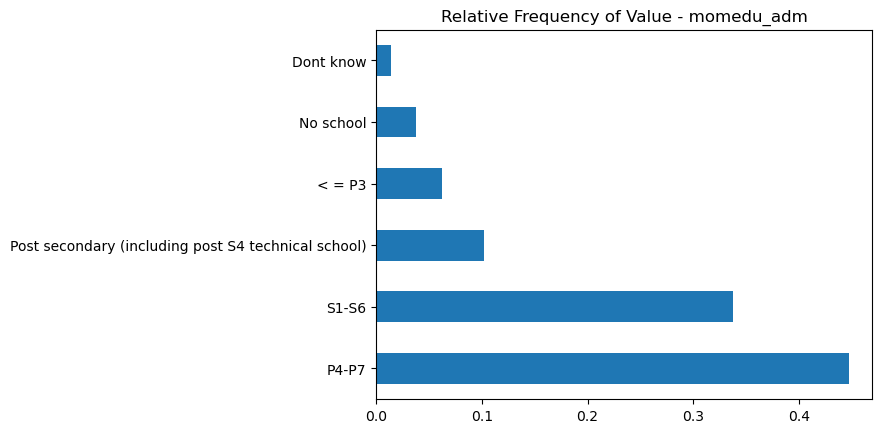

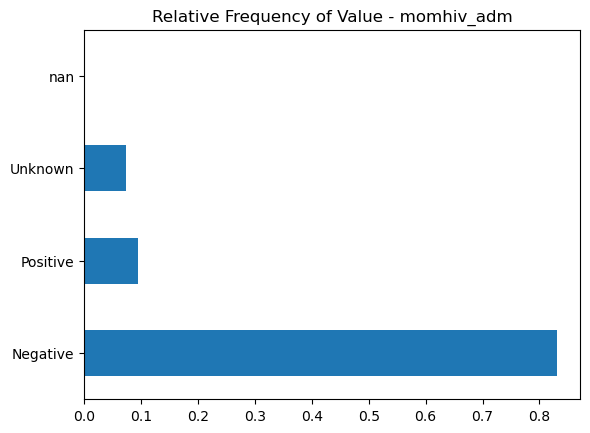

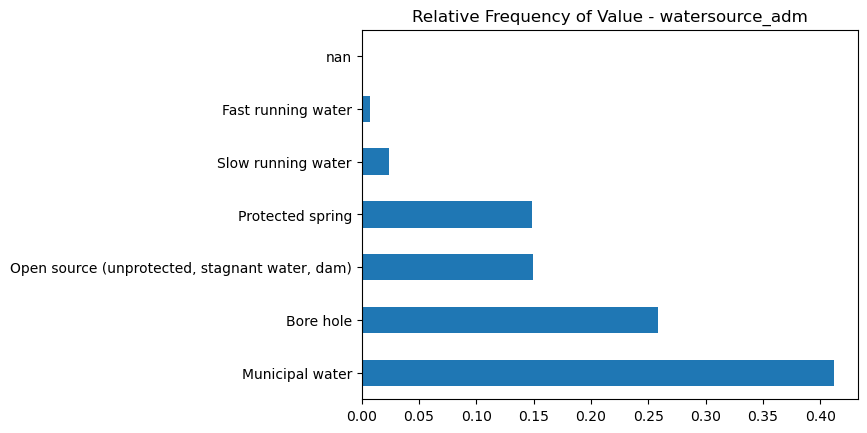

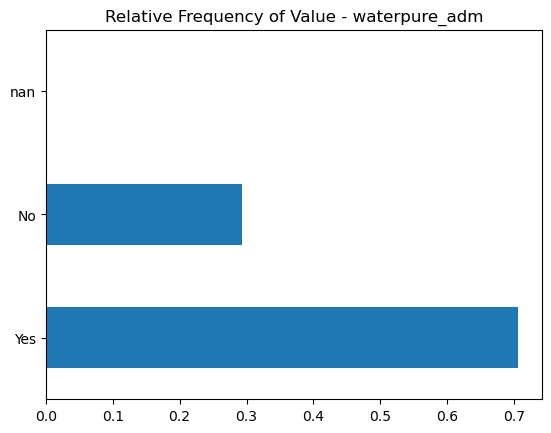

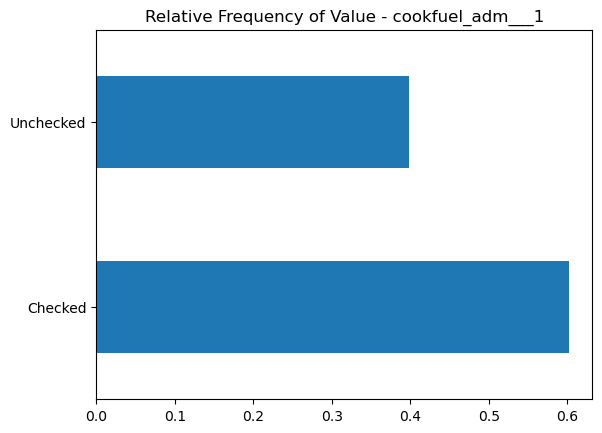

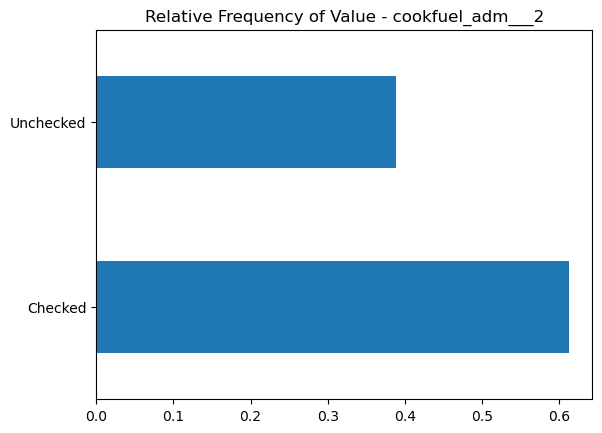

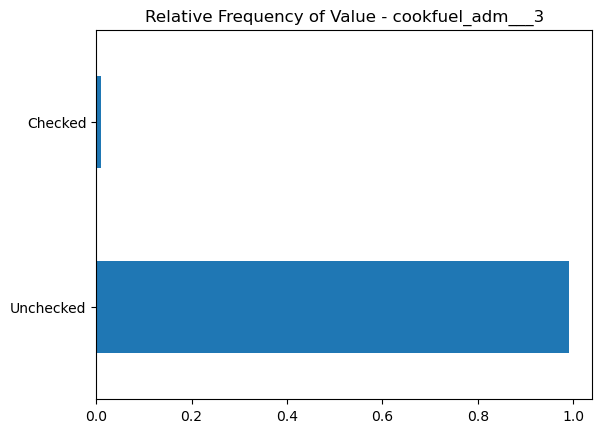

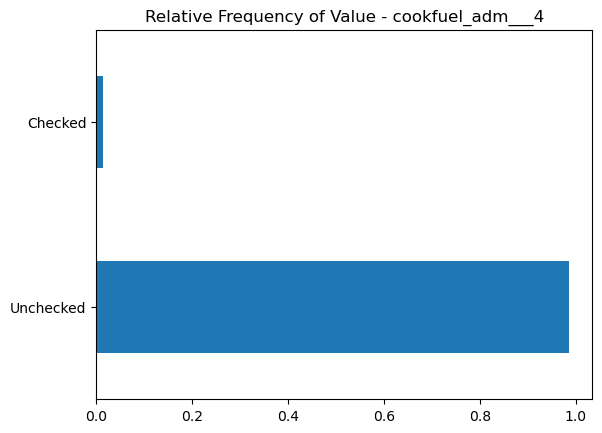

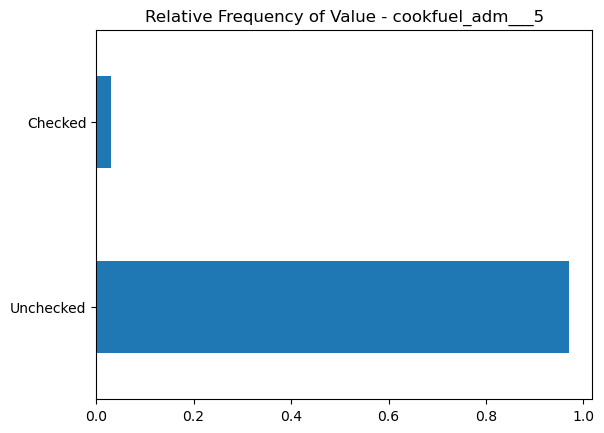

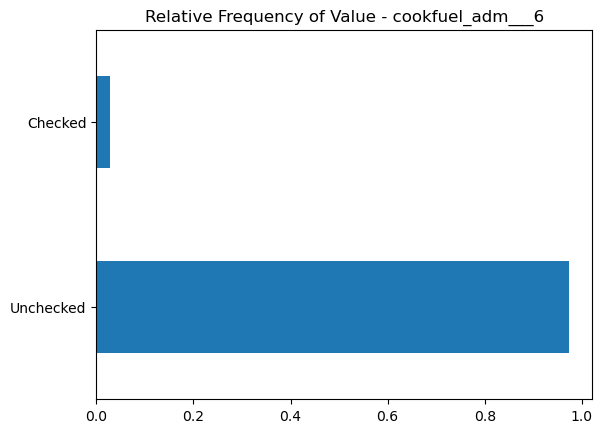

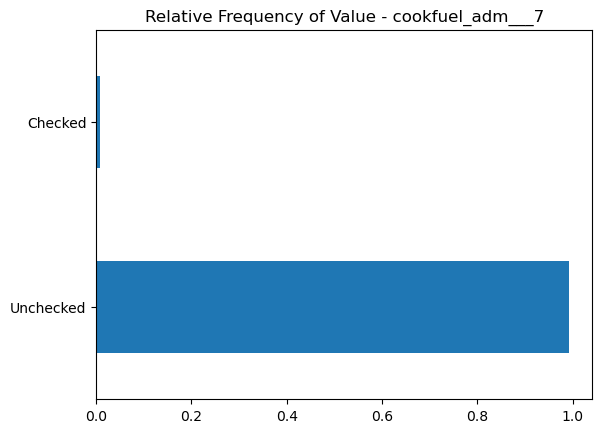

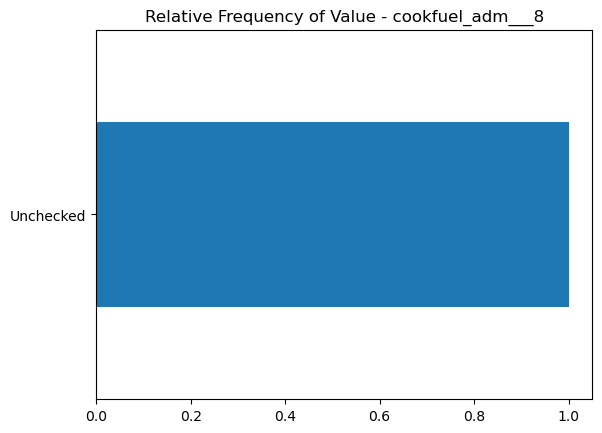

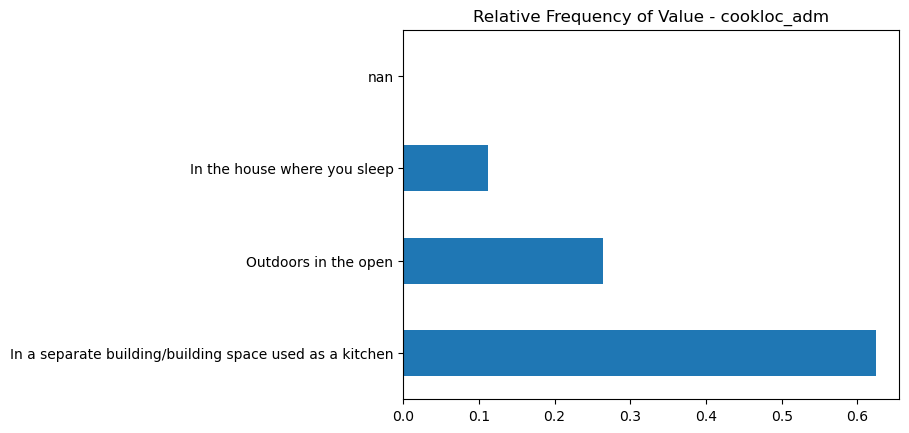

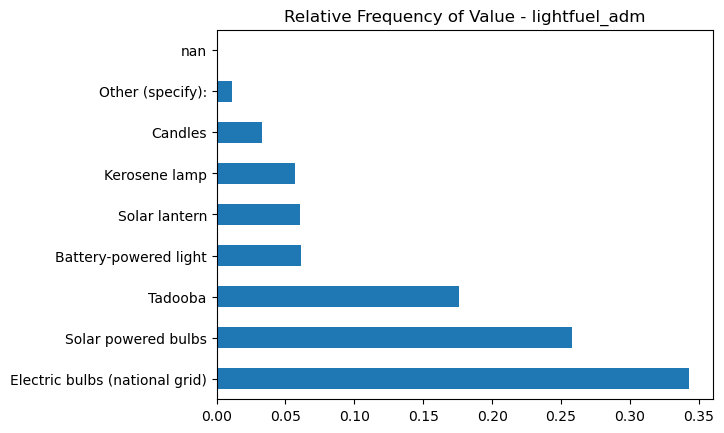

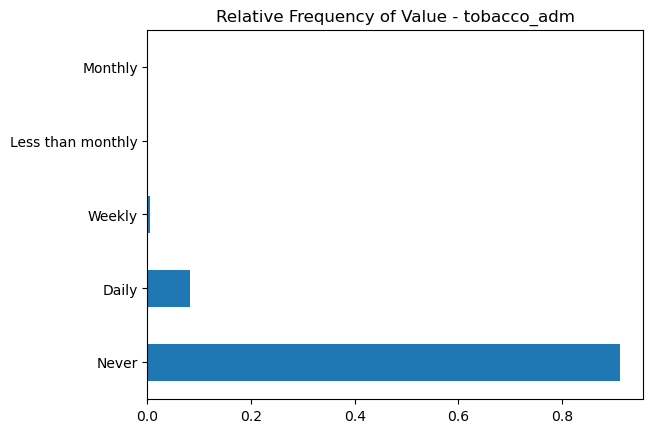

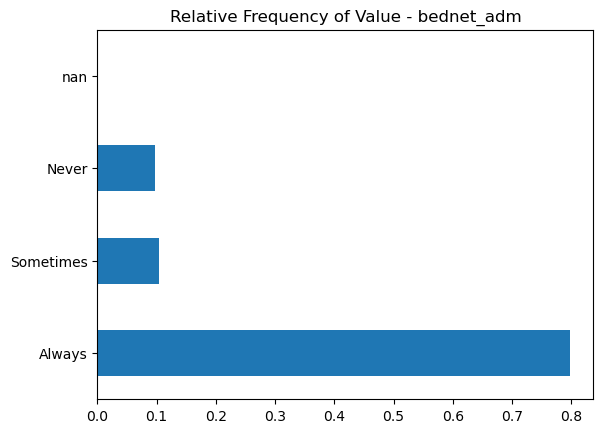

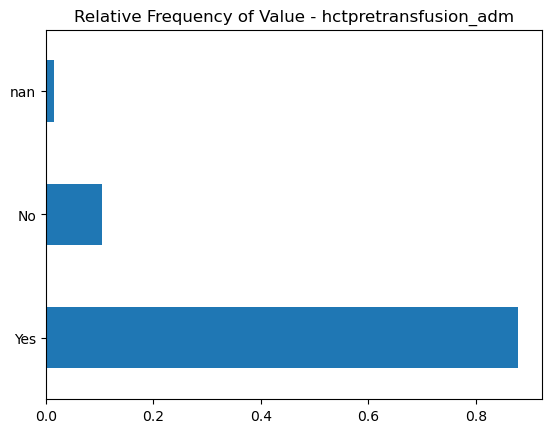

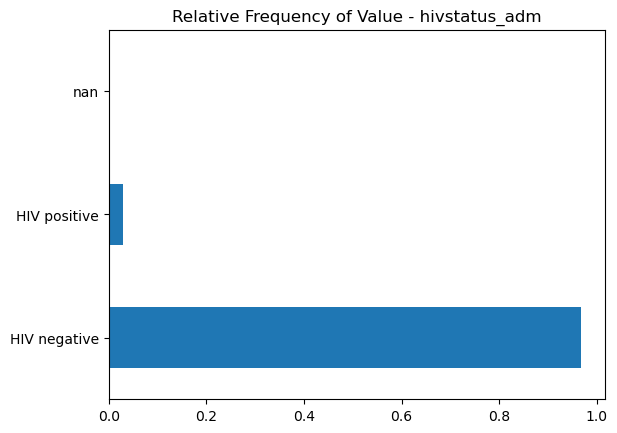

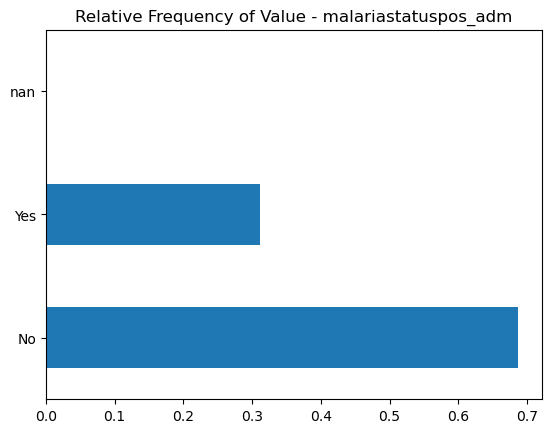

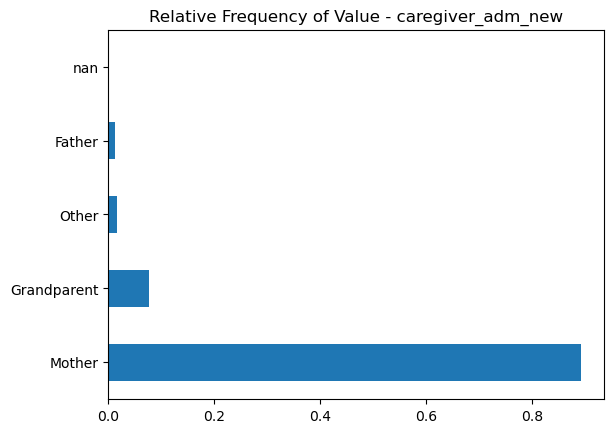

In [10]:
for column in data.select_dtypes("object"):
    data[column].value_counts(normalize=True, dropna=False).plot(kind="barh")
    plt.title(f"Relative Frequency of Value - {column}")
    plt.show()

#### The outcome

In [11]:
data['inhospital_mortality'].value_counts(normalize=True)

0    0.955696
1    0.044304
Name: inhospital_mortality, dtype: float64